# Hospital Length of Stay Prediction

Capstone Project

## Problem Statement

Hospital Length of Stay Prediction



Hospitals need to estimate how long a patient is likely to stay after admission. Accurate prediction of Length of Stay (LOS) helps hospitals:


Optimize bed allocation

Improve resource planning

Reduce operational costs

Improve patient care

Minimize overcrowding

The objective of this project is to build a machine learning model that predicts the number of days a patient will stay in the hospital using demographic information, medical history, vital signs, and laboratory results.

.

- problem of statement

- collection of data

- understanding of data


- statistical analysis

- Data preprocessing 





# for solving this issue , i was collect the data from kaggle

# 1. understanding of data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Dataset


In [2]:
df=pd.read_csv(r"C:\Users\LakshmanAIMLHYD\Desktop\AI&ML(7-8)\4.ML\1.3 LengthOfStay.csv")

In [3]:

df.head()


,eid,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,1,8/29/2012,0,F,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,9/1/2012,B,3
1,2,5/26/2012,5+,F,0,0,0,0,0,0,...,94.078507,8.0,0.943164,28.460516,61,6.5,1,6/2/2012,A,7
2,3,9/22/2012,1,F,0,0,0,0,0,0,...,130.530524,12.0,1.065750,28.843812,64,6.5,2,9/25/2012,B,3
3,4,8/9/2012,0,F,0,0,0,0,0,0,...,163.377028,12.0,0.906862,27.959007,76,6.5,1,8/10/2012,A,1
4,5,12/20/2012,0,F,0,0,0,1,0,1,...,94.886654,11.5,1.242854,30.258927,67,5.6,2,12/24/2012,E,4


In [4]:
df.tail()

,eid,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
99995,99996,1/28/2012,3,M,0,0,0,0,0,0,...,171.422555,12.0,0.650323,30.063069,80,6.5,1,2/3/2012,B,6
99996,99997,8/6/2012,0,M,0,0,0,0,0,0,...,122.342450,12.0,1.521424,28.969548,61,6.5,1,8/7/2012,B,1
99997,99998,7/23/2012,1,M,0,0,1,0,0,0,...,108.288106,12.0,1.025677,26.354919,61,6.9,1,7/27/2012,C,4
99998,99999,12/19/2012,0,M,0,0,0,0,0,0,...,111.750731,16.0,1.035400,29.193462,59,5.6,1,12/23/2012,B,4
99999,100000,3/6/2012,0,F,0,0,0,0,0,0,...,149.572205,12.0,0.813004,25.175760,74,6.5,4,3/8/2012,B,2


In [5]:
df.shape

(100000, 28)

In [6]:
df.shape[0]

100000

In [7]:
df.shape[1]

28

In [8]:
df.head(1)

,eid,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,1,8/29/2012,0,F,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,9/1/2012,B,3


In [9]:
df.rcount.value_counts()

rcount
0     55031
1     15007
2      9987
3      8047
4      6941
5+     4987
Name: count, dtype: int64

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   eid                         100000 non-null  int64  
 1   vdate                       100000 non-null  str    
 2   rcount                      100000 non-null  str    
 3   gender                      100000 non-null  str    
 4   dialysisrenalendstage       100000 non-null  int64  
 5   asthma                      100000 non-null  int64  
 6   irondef                     100000 non-null  int64  
 7   pneum                       100000 non-null  int64  
 8   substancedependence         100000 non-null  int64  
 9   psychologicaldisordermajor  100000 non-null  int64  
 10  depress                     100000 non-null  int64  
 11  psychother                  100000 non-null  int64  
 12  fibrosisandother            100000 non-null  int64  
 13  malnutrition              

# Data Insights

vdate in object, we have to chnage either int or data&time format

rcount in object , we have to chnage int

discharge in object , we have to change either int or date&time format

In [11]:
df.dtypes

eid                             int64
vdate                             str
rcount                            str
gender                            str
dialysisrenalendstage           int64
asthma                          int64
irondef                         int64
pneum                           int64
substancedependence             int64
psychologicaldisordermajor      int64
depress                         int64
psychother                      int64
fibrosisandother                int64
malnutrition                    int64
hemo                            int64
hematocrit                    float64
neutrophils                   float64
sodium                        float64
glucose                       float64
bloodureanitro                float64
creatinine                    float64
bmi                           float64
pulse                           int64
respiration                   float64
secondarydiagnosisnonicd9       int64
discharged                        str
facid       

In [12]:
df.columns

Index(['eid', 'vdate', 'rcount', 'gender', 'dialysisrenalendstage', 'asthma',
       'irondef', 'pneum', 'substancedependence', 'psychologicaldisordermajor',
       'depress', 'psychother', 'fibrosisandother', 'malnutrition', 'hemo',
       'hematocrit', 'neutrophils', 'sodium', 'glucose', 'bloodureanitro',
       'creatinine', 'bmi', 'pulse', 'respiration',
       'secondarydiagnosisnonicd9', 'discharged', 'facid', 'lengthofstay'],
      dtype='str')

# 2. Statistical Analysis

In [13]:
print(df.bloodureanitro.value_counts(normalize=True))

bloodureanitro
12.000000     0.45404
9.000000      0.04120
10.000000     0.03913
11.000000     0.03722
13.000000     0.03469
               ...   
6.600000      0.00003
37.750000     0.00003
223.500000    0.00003
6.142857      0.00003
474.000000    0.00002
Name: proportion, Length: 261, dtype: float64


<Axes: >

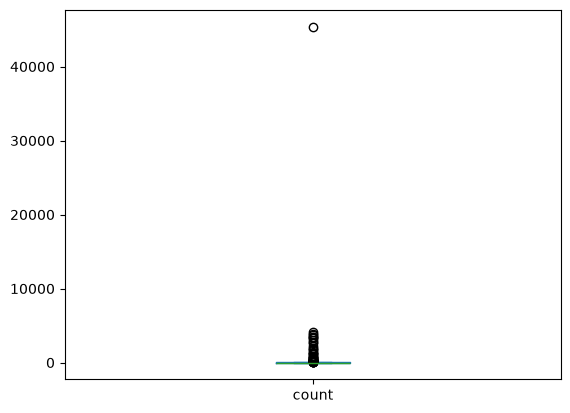

In [14]:
df.bloodureanitro.value_counts().plot(kind='box')

In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
eid,100000.0,50000.500000,28867.657797,1.000000,25000.750000,50000.500000,75000.250000,100000.000000
dialysisrenalendstage,100000.0,0.036420,0.187334,0.000000,0.000000,0.000000,0.000000,1.000000
asthma,100000.0,0.035270,0.184462,0.000000,0.000000,0.000000,0.000000,1.000000
irondef,100000.0,0.094940,0.293134,0.000000,0.000000,0.000000,0.000000,1.000000
pneum,100000.0,0.039450,0.194664,0.000000,0.000000,0.000000,0.000000,1.000000
substancedependence,100000.0,0.063060,0.243072,0.000000,0.000000,0.000000,0.000000,1.000000
psychologicaldisordermajor,100000.0,0.239040,0.426499,0.000000,0.000000,0.000000,0.000000,1.000000
depress,100000.0,0.051660,0.221341,0.000000,0.000000,0.000000,0.000000,1.000000
psychother,100000.0,0.049390,0.216682,0.000000,0.000000,0.000000,0.000000,1.000000
fibrosisandother,100000.0,0.004790,0.069044,0.000000,0.000000,0.000000,0.000000,1.000000


- bloodureanitro: has chance of outlier


secondarydiagnosisnonicd has chance of outlier

In [16]:
df.head(1)

,eid,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,1,8/29/2012,0,F,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,9/1/2012,B,3


In [17]:
df.dtypes

eid                             int64
vdate                             str
rcount                            str
gender                            str
dialysisrenalendstage           int64
asthma                          int64
irondef                         int64
pneum                           int64
substancedependence             int64
psychologicaldisordermajor      int64
depress                         int64
psychother                      int64
fibrosisandother                int64
malnutrition                    int64
hemo                            int64
hematocrit                    float64
neutrophils                   float64
sodium                        float64
glucose                       float64
bloodureanitro                float64
creatinine                    float64
bmi                           float64
pulse                           int64
respiration                   float64
secondarydiagnosisnonicd9       int64
discharged                        str
facid       

 - vdate dtype wrong so convert string into int or datatime

 discharged dtype wrong so convert string into int or datatime
 

In [18]:
df.describe(include="object").T

C:\Users\LakshmanAIMLHYD\AppData\Local\Temp\ipykernel_5276\1274302342.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").T


,count,unique,top,freq
vdate,100000,367,10/3/2012,333
rcount,100000,6,0,55031
gender,100000,2,F,57643
discharged,100000,378,2/16/2012,316
facid,100000,5,E,30755


# 3.Data Pre-Processing

In [19]:
df.rcount.value_counts()

rcount
0     55031
1     15007
2      9987
3      8047
4      6941
5+     4987
Name: count, dtype: int64

In [20]:
# df["vdate"]=df["vdate"].astype("int")

df["vdate"]=pd.to_datetime(df["vdate"])

df["rcount"]=df["rcount"].str.replace("+","",regex=False).astype(int)



In [21]:
df.rcount.value_counts()

rcount
0    55031
1    15007
2     9987
3     8047
4     6941
5     4987
Name: count, dtype: int64

In [22]:
df["discharged"]=pd.to_datetime(df["discharged"])

In [23]:
df.dtypes

eid                                    int64
vdate                         datetime64[us]
rcount                                 int64
gender                                   str
dialysisrenalendstage                  int64
asthma                                 int64
irondef                                int64
pneum                                  int64
substancedependence                    int64
psychologicaldisordermajor             int64
depress                                int64
psychother                             int64
fibrosisandother                       int64
malnutrition                           int64
hemo                                   int64
hematocrit                           float64
neutrophils                          float64
sodium                               float64
glucose                              float64
bloodureanitro                       float64
creatinine                           float64
bmi                                  float64
pulse     

In [24]:
df.isnull().sum()

eid                           0
vdate                         0
rcount                        0
gender                        0
dialysisrenalendstage         0
asthma                        0
irondef                       0
pneum                         0
substancedependence           0
psychologicaldisordermajor    0
depress                       0
psychother                    0
fibrosisandother              0
malnutrition                  0
hemo                          0
hematocrit                    0
neutrophils                   0
sodium                        0
glucose                       0
bloodureanitro                0
creatinine                    0
bmi                           0
pulse                         0
respiration                   0
secondarydiagnosisnonicd9     0
discharged                    0
facid                         0
lengthofstay                  0
dtype: int64

In [25]:
df.duplicated().sum()

np.int64(0)

# 4.EDA

In [26]:
df.dtypes

eid                                    int64
vdate                         datetime64[us]
rcount                                 int64
gender                                   str
dialysisrenalendstage                  int64
asthma                                 int64
irondef                                int64
pneum                                  int64
substancedependence                    int64
psychologicaldisordermajor             int64
depress                                int64
psychother                             int64
fibrosisandother                       int64
malnutrition                           int64
hemo                                   int64
hematocrit                           float64
neutrophils                          float64
sodium                               float64
glucose                              float64
bloodureanitro                       float64
creatinine                           float64
bmi                                  float64
pulse     

In [27]:
df.shape

(100000, 28)

In [28]:
df.drop("eid",axis=1,inplace=True)

In [29]:
df.shape

(100000, 27)

In [30]:
df.head(1)

,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,2012-08-29,0,F,0,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,2012-09-01,B,3


In [31]:
# numeric_features=[feature for feature in df.columns if df[feature].dtype != "O"]

# categorical_features=[feature for feature in df.columns if df[feature].dtype == "O"]

numeric_features = df.select_dtypes(include=["number"]).columns.tolist()

categorical_features = df.select_dtypes(include=["object","category"]).columns.tolist()

datetime_features = df.select_dtypes(include=["datetime"]).columns.tolist()

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('\nWe have {} categorical features : {}'.format(len(categorical_features), categorical_features))
print("\n we have {} datetime features :{}".format(len(datetime_features ),datetime_features ))

We have 23 numerical features : ['rcount', 'dialysisrenalendstage', 'asthma', 'irondef', 'pneum', 'substancedependence', 'psychologicaldisordermajor', 'depress', 'psychother', 'fibrosisandother', 'malnutrition', 'hemo', 'hematocrit', 'neutrophils', 'sodium', 'glucose', 'bloodureanitro', 'creatinine', 'bmi', 'pulse', 'respiration', 'secondarydiagnosisnonicd9', 'lengthofstay']

We have 2 categorical features : ['gender', 'facid']

 we have 2 datetime features :['vdate', 'discharged']


C:\Users\LakshmanAIMLHYD\AppData\Local\Temp\ipykernel_5276\3683324094.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=["object","category"]).columns.tolist()


In [32]:
# Alternative
# numeric_features = df.select_dtypes(include=["number"]).columns.tolist()

# categorical_features = df.select_dtypes(include=["object","category"]).columns.tolist()

# datetime_features = df.select_dtypes(include=["datetime"]).columns.tolist()

In [33]:
numeric_features

['rcount',
 'dialysisrenalendstage',
 'asthma',
 'irondef',
 'pneum',
 'substancedependence',
 'psychologicaldisordermajor',
 'depress',
 'psychother',
 'fibrosisandother',
 'malnutrition',
 'hemo',
 'hematocrit',
 'neutrophils',
 'sodium',
 'glucose',
 'bloodureanitro',
 'creatinine',
 'bmi',
 'pulse',
 'respiration',
 'secondarydiagnosisnonicd9',
 'lengthofstay']

In [34]:
categorical_features

['gender', 'facid']

In [35]:
df.rcount.value_counts()

rcount
0    55031
1    15007
2     9987
3     8047
4     6941
5     4987
Name: count, dtype: int64

In [36]:
df.dialysisrenalendstage.value_counts()

dialysisrenalendstage
0    96358
1     3642
Name: count, dtype: int64

- *1.Univariate_analysis*

In [37]:
df.asthma.value_counts()

asthma
0    96473
1     3527
Name: count, dtype: int64

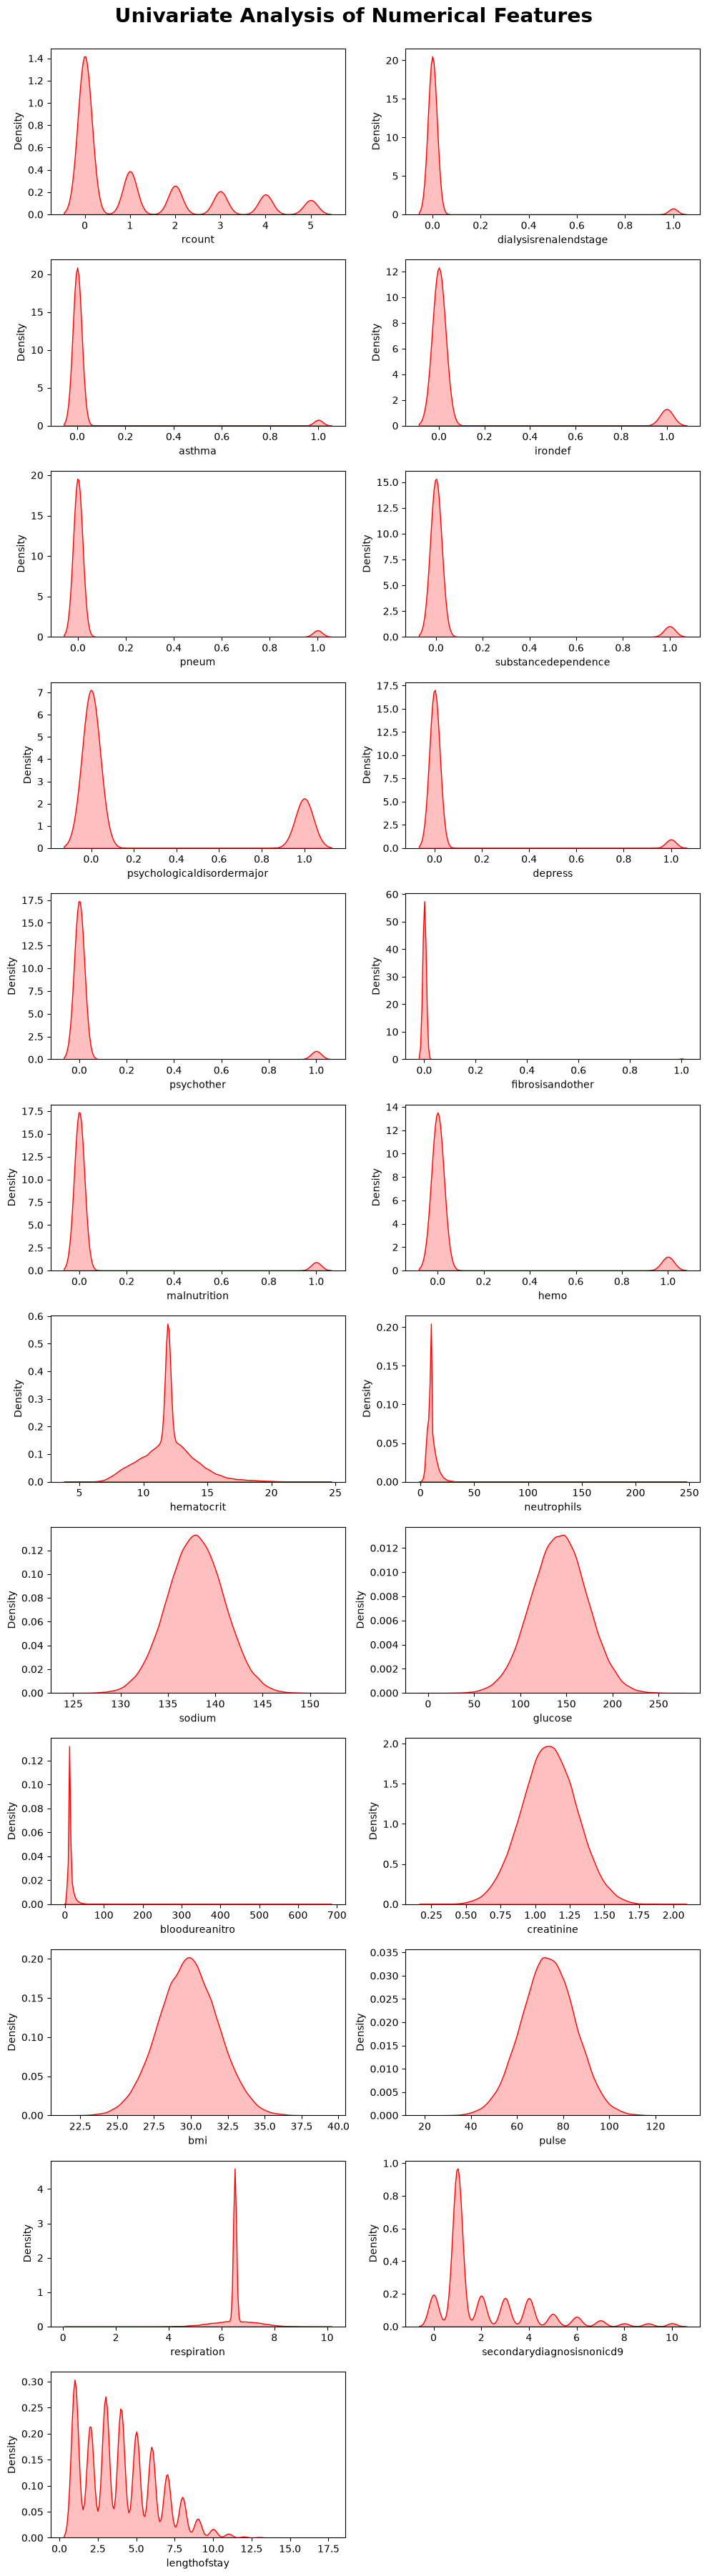

In [38]:
import math


rows = math.ceil(len(numeric_features) / 2)

plt.figure(figsize=(10, 3 * rows))
plt.suptitle( "Univariate Analysis of Numerical Features", fontsize=20, fontweight="bold", y=1.)

for i, col in enumerate(numeric_features):
    plt.subplot(rows, 2, i + 1)
    sns.kdeplot(x=df[col], fill=True, color="red")
    plt.xlabel(col)

plt.tight_layout()
plt.show()

In [39]:
df.head(1)

,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,2012-08-29,0,F,0,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,2012-09-01,B,3


- hemotocrit outlier -->right tail


- bloodureanitro	 outlier --> right tail

- neutrophil  outlers---> right tail 

- respiration outliers --> right outlier

- secondarydiagnosisnonicd9  outlier ---> right tail

C:\Users\LakshmanAIMLHYD\AppData\Local\Temp\ipykernel_5276\2090222580.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot( x=df[col], palette='Set2')
C:\Users\LakshmanAIMLHYD\AppData\Local\Temp\ipykernel_5276\2090222580.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot( x=df[col], palette='Set2')


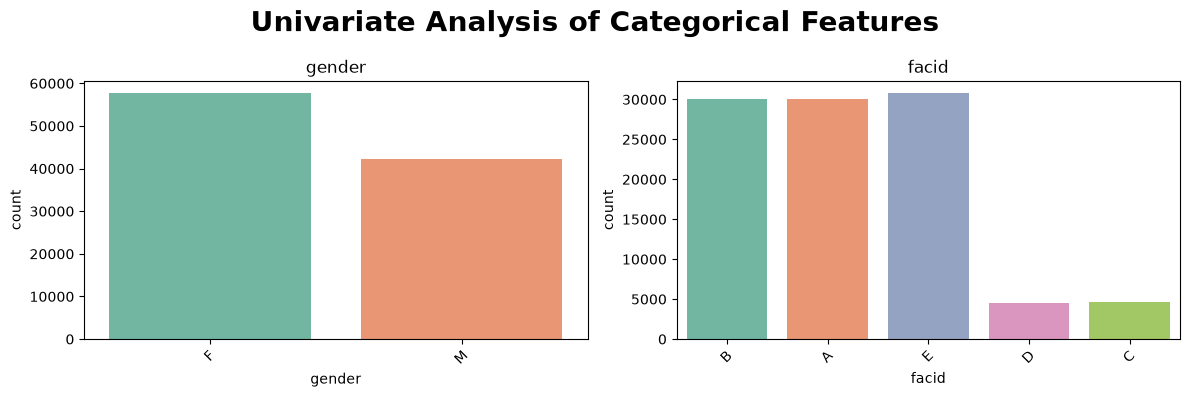

In [40]:
import math

rows = math.ceil(len(categorical_features) / 2)

plt.figure(figsize=(12, 4 * rows))
plt.suptitle(
    'Univariate Analysis of Categorical Features', fontsize=20, fontweight='bold')

for i, col in enumerate(categorical_features):
    plt.subplot(rows, 2, i + 1)
    sns.countplot( x=df[col], palette='Set2')
    plt.title(col)
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show();

In [41]:
df.head(1)

,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,2012-08-29,0,F,0,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,2012-09-01,B,3


In [42]:
df.lengthofstay.value_counts()

lengthofstay
1     17979
3     16068
4     14822
2     12825
5     12116
6     10362
7      7263
8      4652
9      2184
10     1000
11      460
12      137
13       75
14       31
15       16
16        6
17        4
Name: count, dtype: int64

In [43]:
df.head(1)

,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,2012-08-29,0,F,0,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,2012-09-01,B,3


# Bivariate Analysis

- Visualize the Target Feature

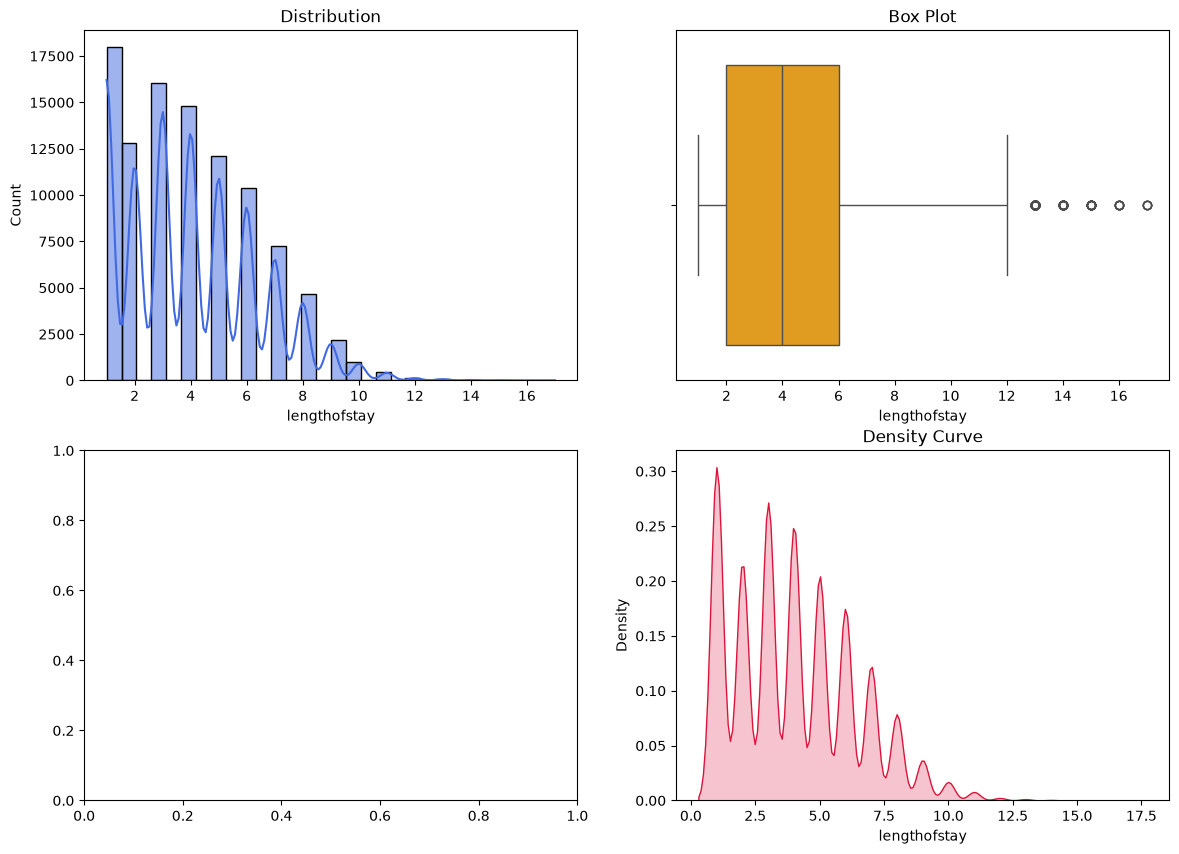

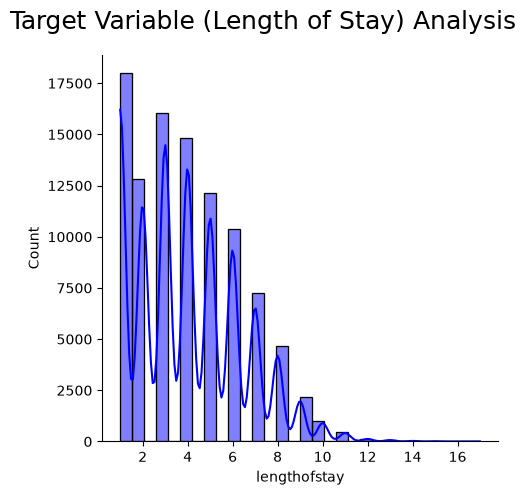

In [44]:


fig, axes = plt.subplots(2, 2, figsize=(14,10))

# Histogram + KDE
sns.histplot(df['lengthofstay'], bins=30, kde=True, ax=axes[0,0], color='royalblue')
axes[0,0].set_title('Distribution')

# Box Plot
sns.boxplot(x=df['lengthofstay'], ax=axes[0,1], color='orange')
axes[0,1].set_title('Box Plot')


# KDE Plot
sns.kdeplot(df['lengthofstay'], fill=True, ax=axes[1,1], color='crimson')
axes[1,1].set_title('Density Curve')


sns.displot(
    df['lengthofstay'],
    bins=30,
    kde=True,
    color='blue',
    edgecolor='black'
)

plt.suptitle('Target Variable (Length of Stay) Analysis', fontsize=18)

plt.tight_layout()

plt.show()

In [45]:
df.head(1)

,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,2012-08-29,0,F,0,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,2012-09-01,B,3


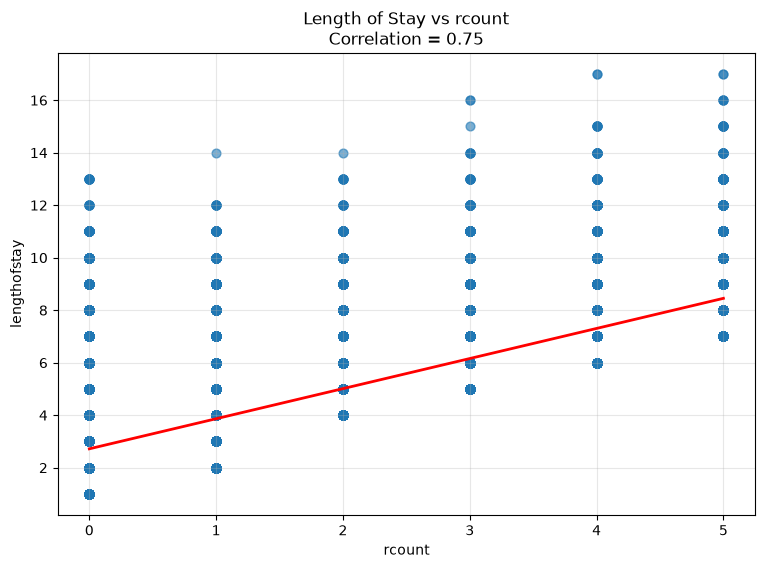

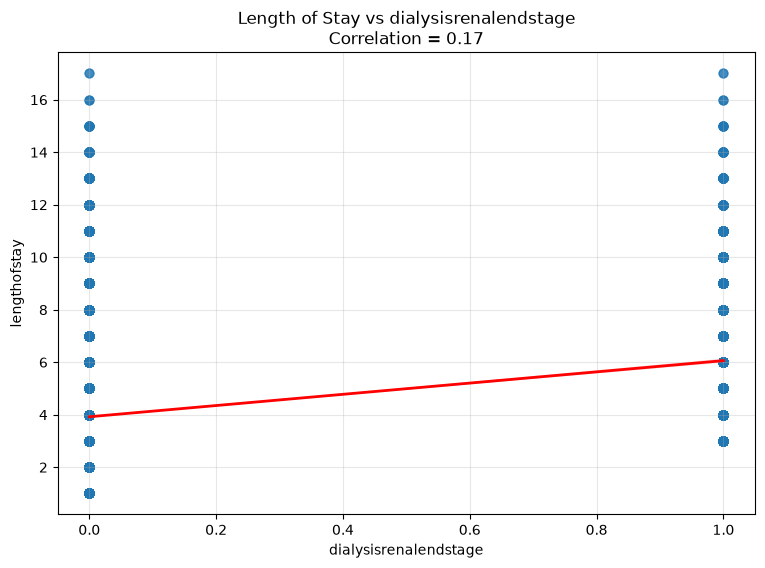

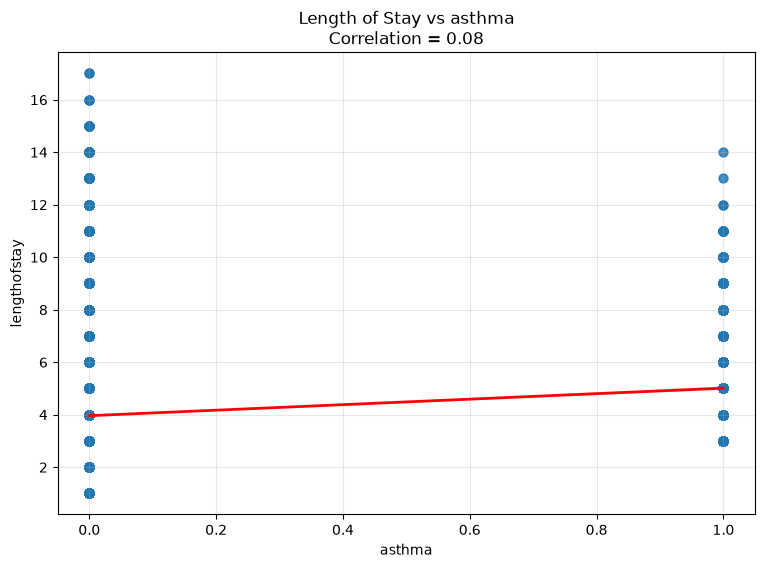

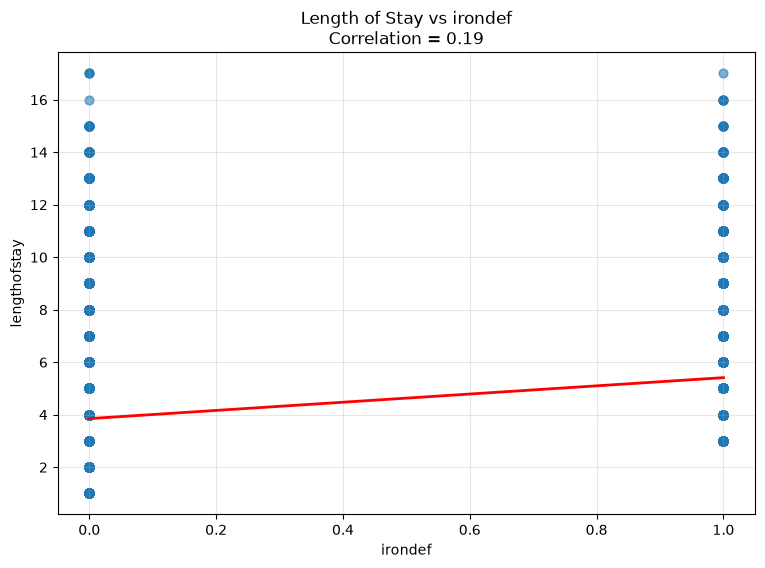

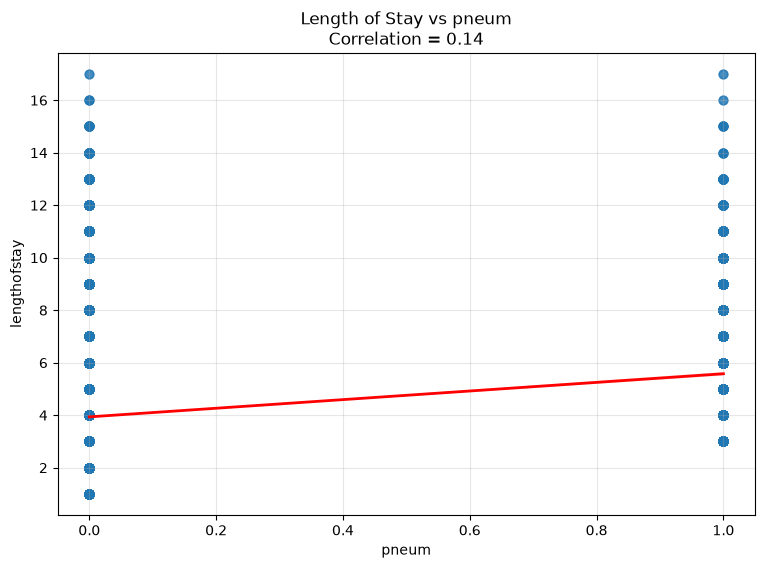

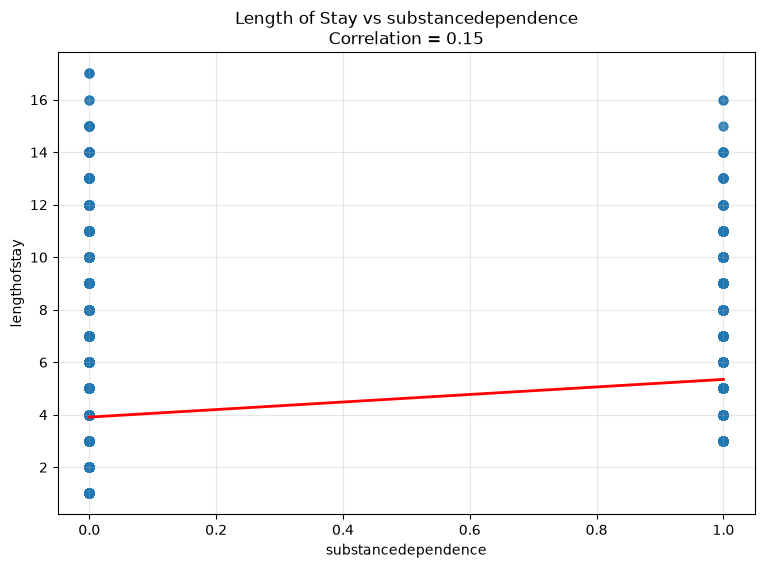

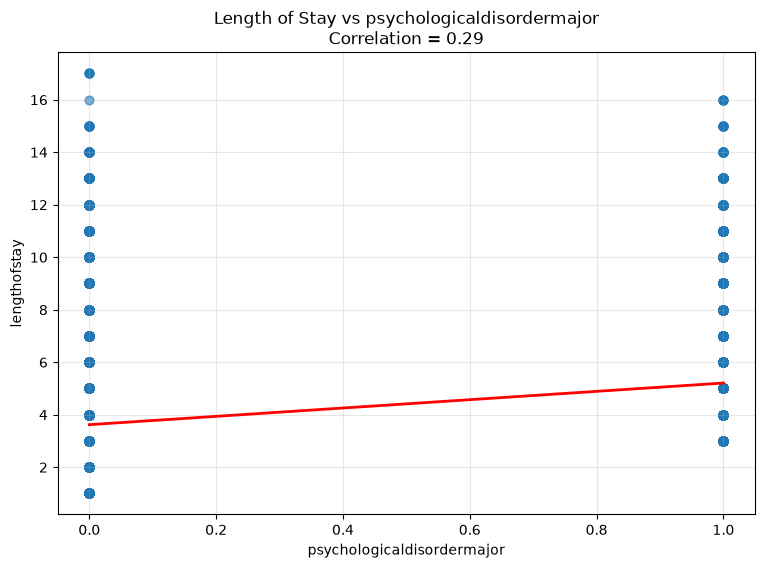

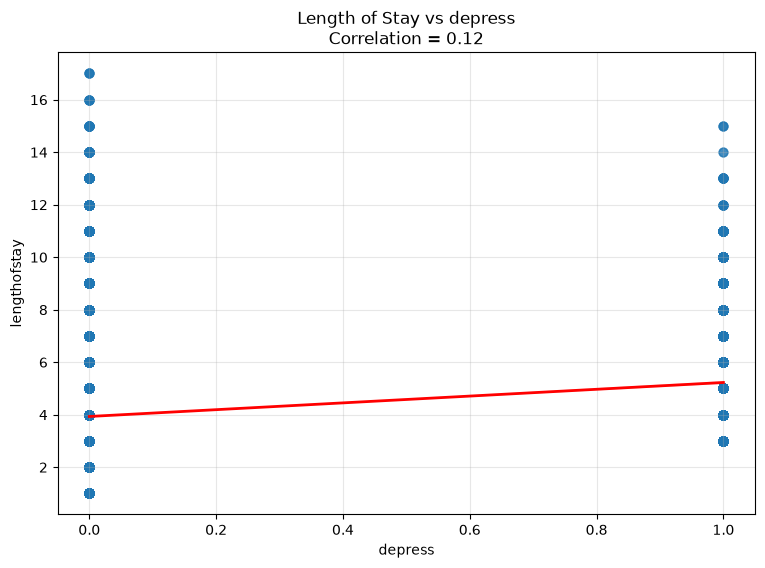

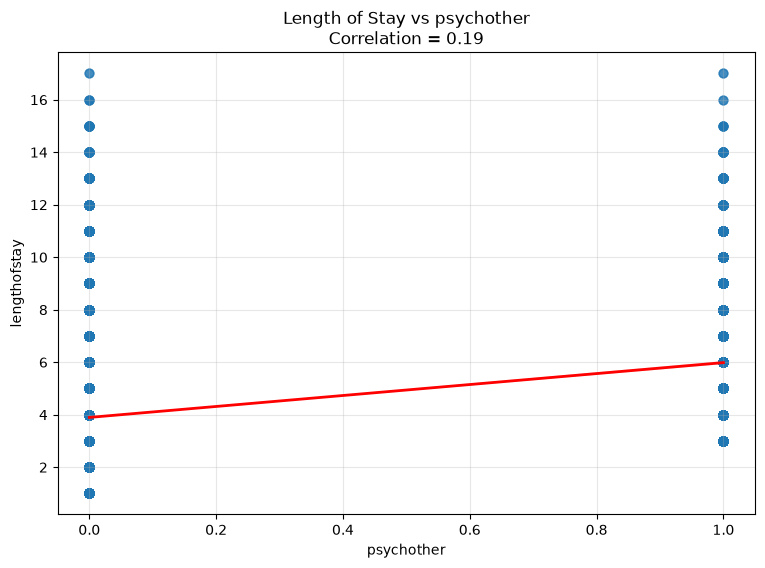

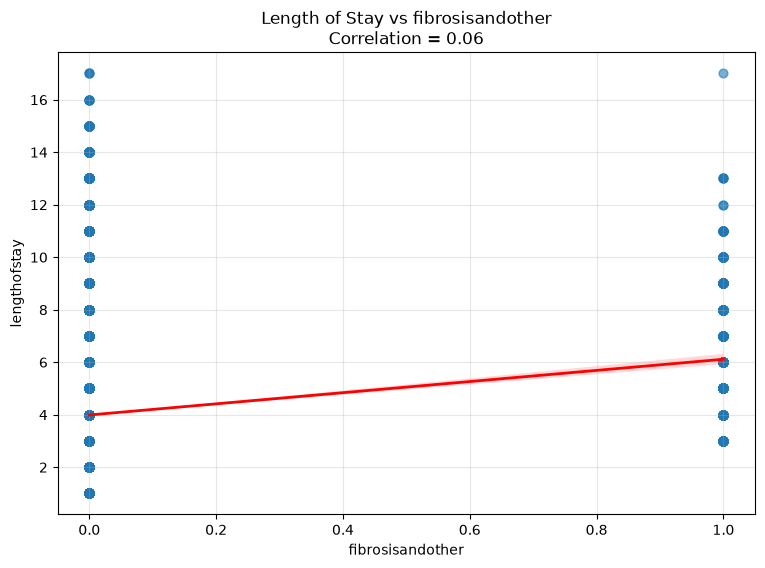

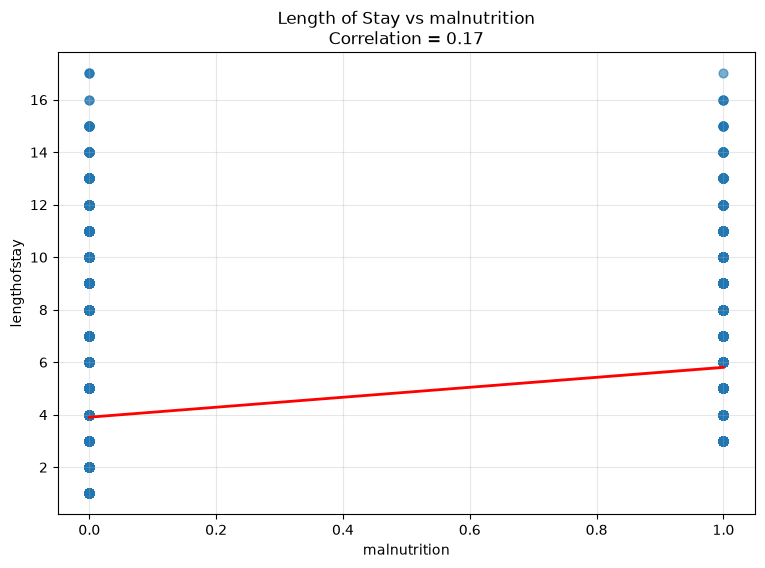

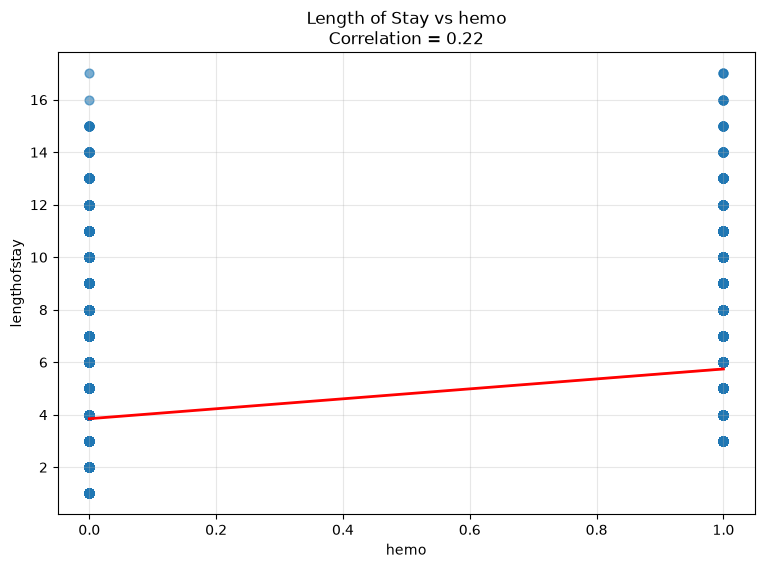

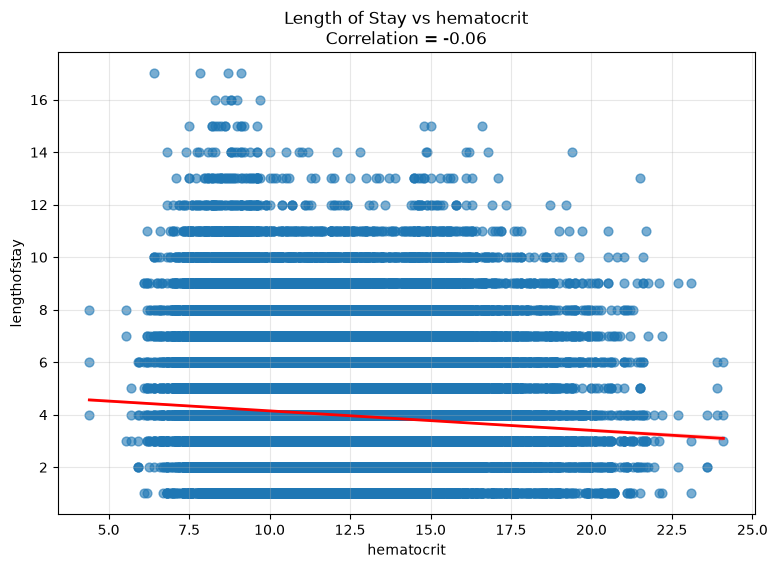

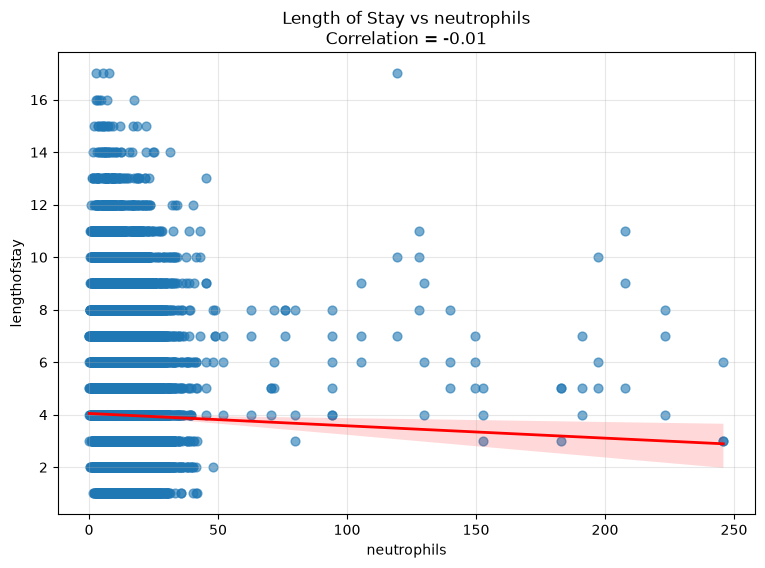

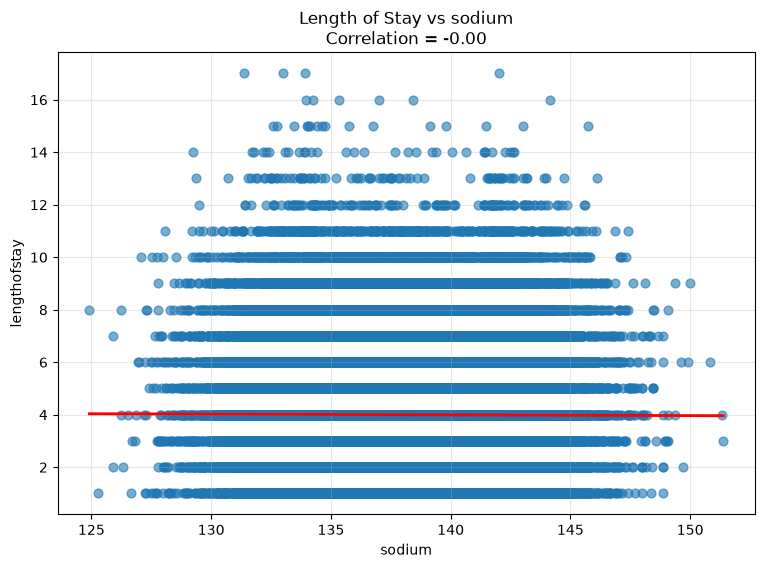

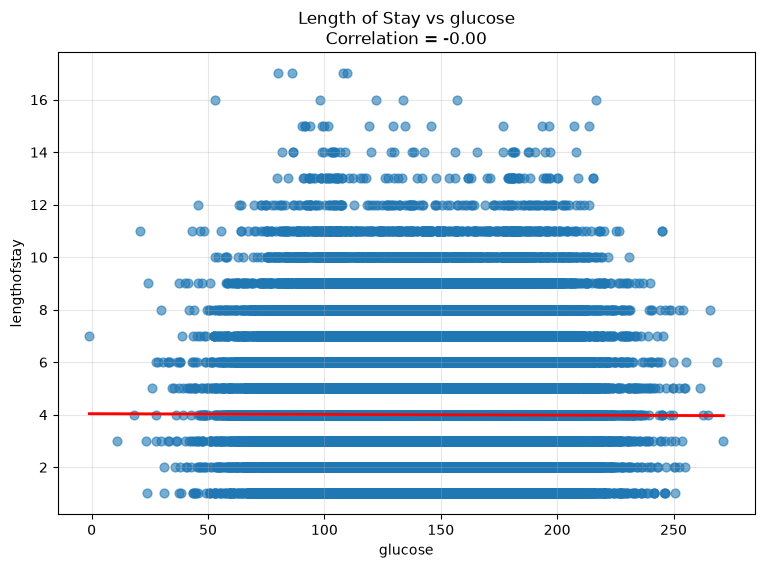

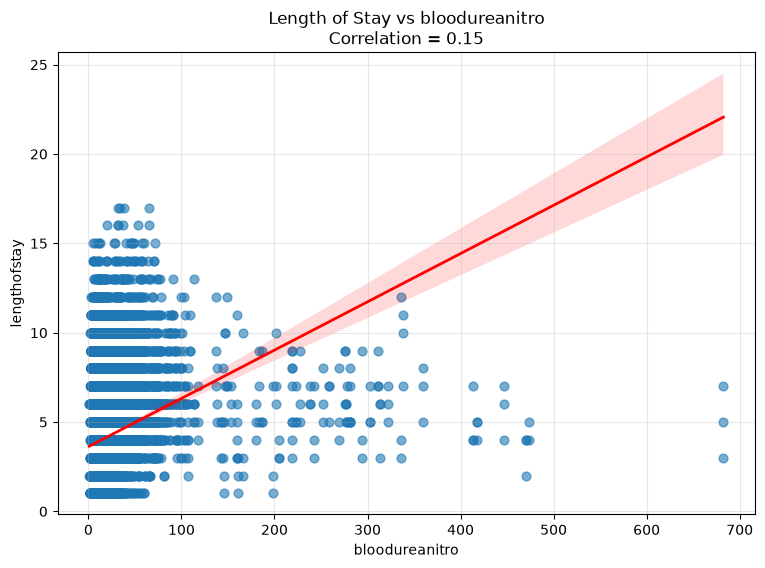

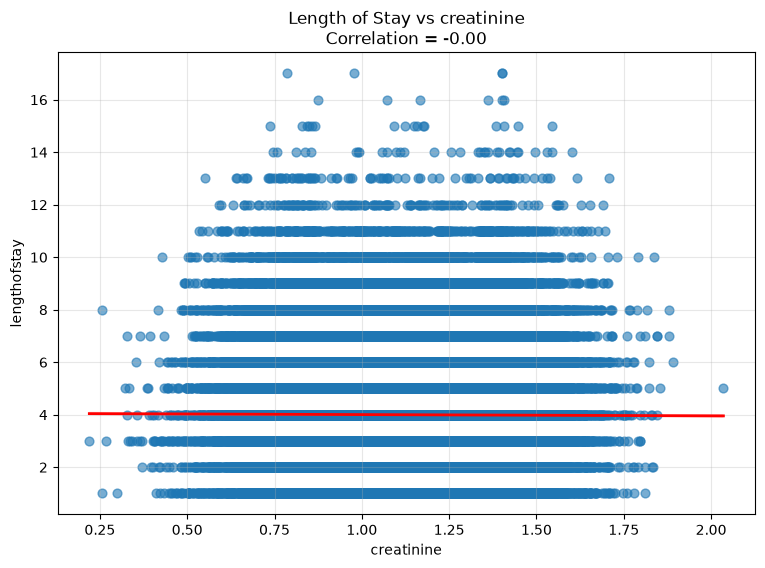

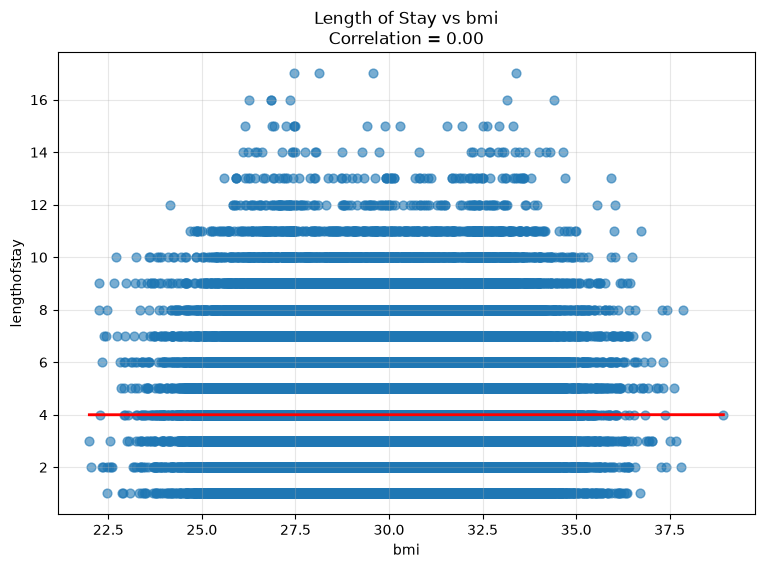

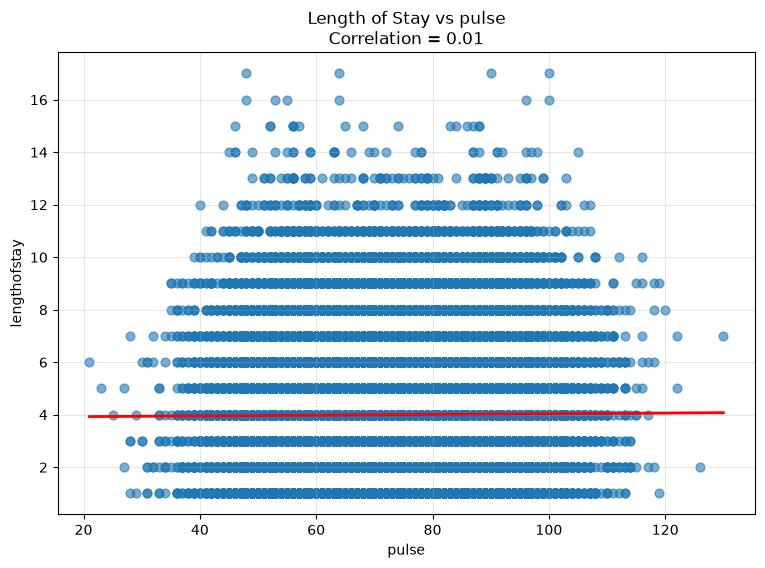

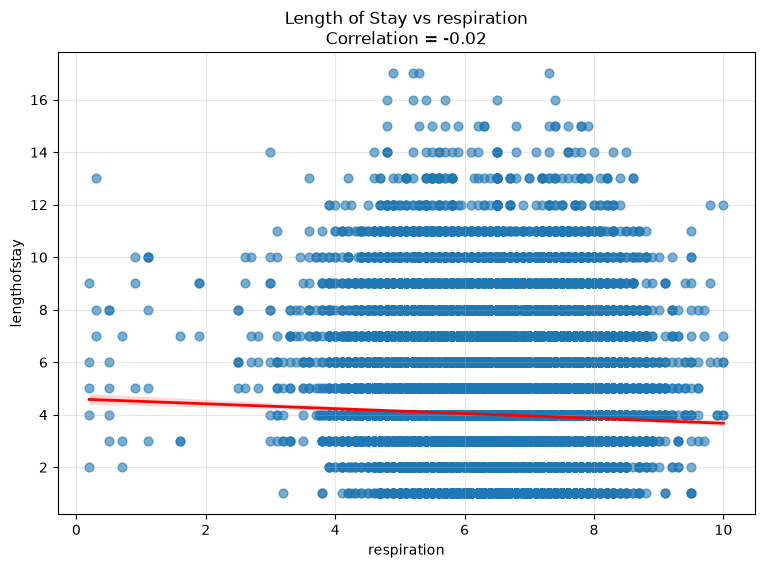

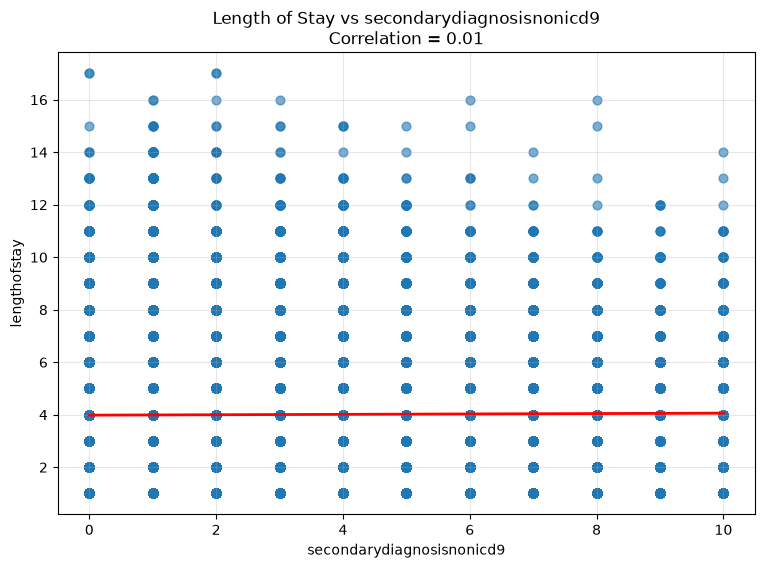

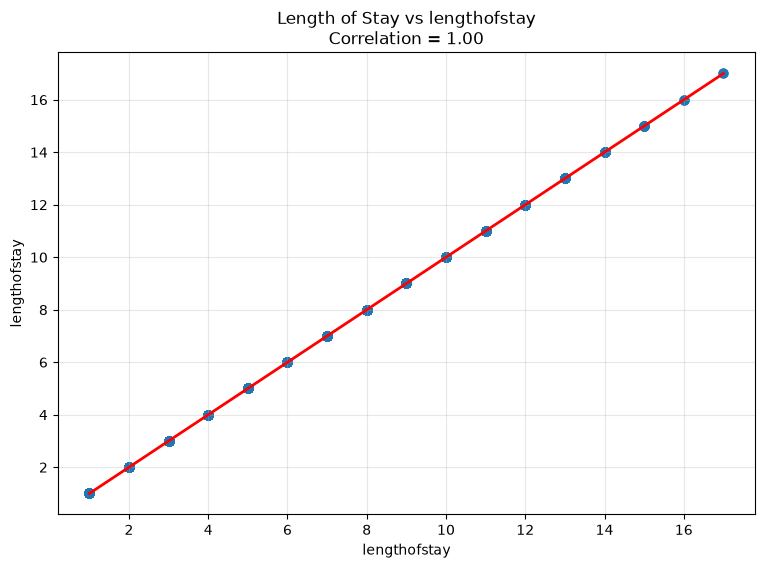

In [46]:
plot_numeric_features = [col for col in numeric_features if pd.api.types.is_numeric_dtype(df[col])]

for col in plot_numeric_features:

    plt.figure(figsize=(9,6))
    feature = df[col]
    label = df['lengthofstay']
    correlation = feature.corr(label)
    sns.regplot(
          x=feature, y='lengthofstay',data=df,scatter_kws={'alpha':0.6, 's':40},
          line_kws={'color':'red', 'linewidth':2},
          )

    plt.title(f'Length of Stay vs {col}\nCorrelation = {correlation:.2f}')
    plt.grid(alpha=0.3)
    plt.show()

In [47]:
print(df[plot_numeric_features].dtypes)

rcount                          int64
dialysisrenalendstage           int64
asthma                          int64
irondef                         int64
pneum                           int64
substancedependence             int64
psychologicaldisordermajor      int64
depress                         int64
psychother                      int64
fibrosisandother                int64
malnutrition                    int64
hemo                            int64
hematocrit                    float64
neutrophils                   float64
sodium                        float64
glucose                       float64
bloodureanitro                float64
creatinine                    float64
bmi                           float64
pulse                           int64
respiration                   float64
secondarydiagnosisnonicd9       int64
lengthofstay                    int64
dtype: object


 **Does  rcount has any impact on lengthofstay ?**

In [48]:

df.groupby('rcount')['lengthofstay'].value_counts(normalize=True).to_frame()*100

proportion
rcount lengthofstay            
0      1              32.670677
       3              25.378423
       2              14.202904
       4              13.932147
       5               7.646599
...                         ...
5      13              0.661720
       14              0.220573
       15              0.180469
       16              0.080209
       17              0.040104

[70 rows x 1 columns]

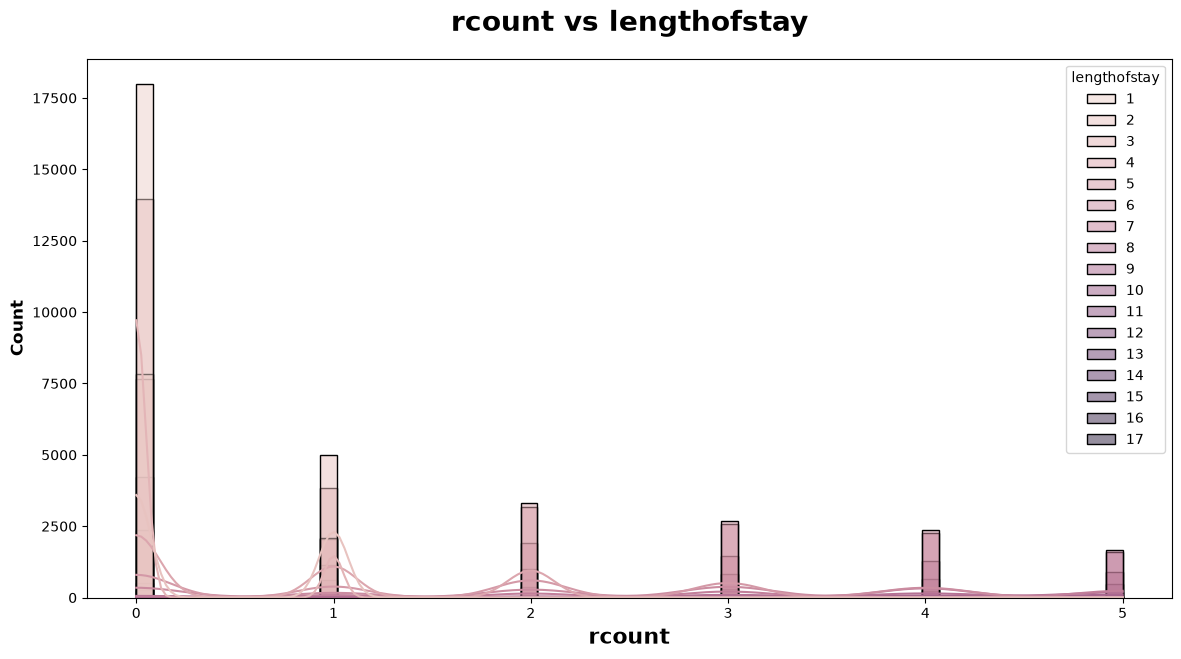

In [49]:
plt.subplots(figsize=(14,7))
sns.histplot(x="rcount",hue="lengthofstay", data=df, kde=True)
plt.title("rcount vs lengthofstay", weight="bold",fontsize=20, pad=20)
plt.xlabel("rcount", weight="bold", fontsize=16)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.show()

 **Does dialysisrenalendstage has any impact on lengthofstay ?**


In [50]:

df.groupby('dialysisrenalendstage')['lengthofstay'].value_counts(normalize=True).to_frame()*100

proportion
dialysisrenalendstage lengthofstay            
0                     1              18.658544
                      3              16.233214
                      4              14.764732
                      2              13.309741
                      5              11.876544
                      6              10.072853
                      7               7.103717
                      8               4.486394
                      9               2.030968
                      10              0.884203
                      11              0.374645
                      12              0.114158
                      13              0.055003
                      14              0.020756
                      15              0.009340
                      16              0.003113
                      17              0.002076
1                     5              18.451400
                      6              18.012081
                      4              16.337177
                      3              11.696870
                      7              11.477210
                      8               9.033498
                      9               6.232839
                      10              4.063701
                      11              2.718287
                      12              0.741351
                      13              0.604064
                      14              0.302032
                      15              0.192202
                      16              0.082372
                      17              0.054915

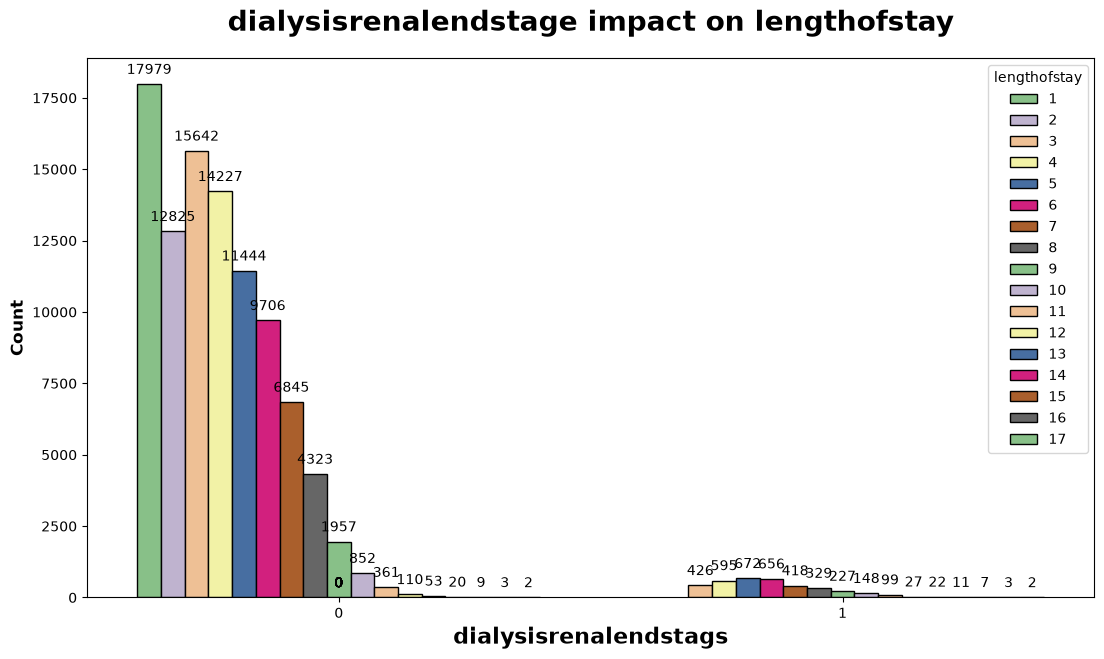

In [51]:
plt.subplots(figsize=(13, 7))
ax = sns.countplot(x="dialysisrenalendstage", hue="lengthofstay", data=df, ec="black", palette="Accent")
plt.title("dialysisrenalendstage impact on lengthofstay", weight="bold", fontsize=20, pad=20)
plt.ylabel("Count", weight="bold", fontsize=12)
plt.xlabel("dialysisrenalendstags", weight="bold", fontsize=16)
plt.legend(title="lengthofstay", fancybox=True)

# Add count values on top of each bar
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'),
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 10),
                textcoords = 'offset points')

plt.show()

In [52]:
df.head(1)

,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,2012-08-29,0,F,0,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,2012-09-01,B,3


# Assignment to complete all remaining

- Multivariate analysis

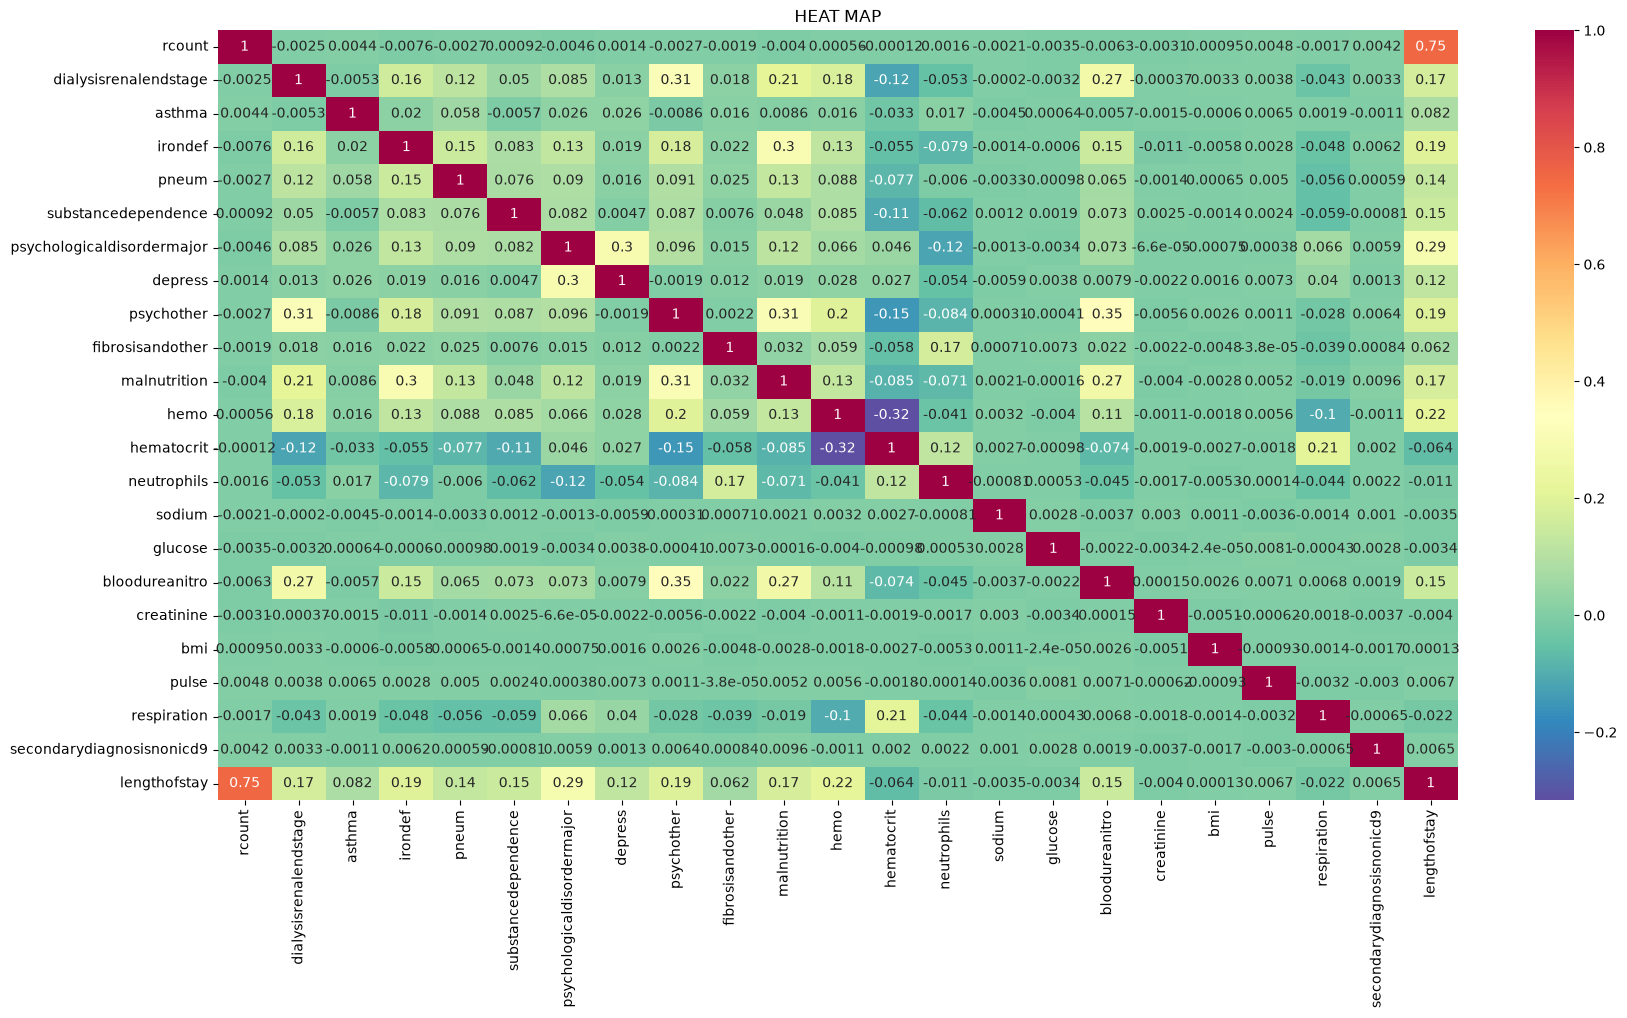

In [53]:
plt.figure (figsize= (20,10))
corelation= df[numeric_features].corr()
sns.heatmap(corelation, annot=True, cmap='Spectral_r')
plt.title("HEAT MAP")
plt.show()

In [54]:
# discrete_features=[feature for feature in numeric_features if len(df[feature].unique())<=25]

# continuous_features=[feature for feature in numeric_features if len(df[feature].unique()) > 25]

# print('We have {} discrete features : {}'.format(len(discrete_features), discrete_features))
# print('\nWe have {} continuous_features : {}'.format(len(continuous_features), continuous_features))

#  Outlier Detection & removal

The most common method is the IQR (Interquartile Range).

Formula
IQR=Q3−Q1

Lower Bound:

Q1−1.5×IQR

Upper Bound:

Q3+1.5×IQR

Any value outside these bounds is considered an outlier.

# Severity of Outliers

| **Range**        | **Interpretation** |
| ---------------- | ------------------ |
| Within 1.5 × IQR | Normal             |
| Beyond 1.5 × IQR | Mild outlier       |
| Beyond 3 × IQR   | Extreme outlier    |

# treatments for outliers

| **Method**                  | **When to Use**                 | **Recommended?**     |
| --------------------------- | ------------------------------- | -------------------- |
| Remove rows                 | Few erroneous records           | ✅ Yes                |
| Median Imputation           | Impossible or missing values    | ✅ Yes                |
| IQR Capping (Winsorization) | Extreme outliers                | ✅ Yes                |
| Log Transformation          | Highly right-skewed data        | ✅ Yes                |
| Square Root Transformation  | Moderately skewed data          | ✅ Yes                |
| Robust Scaling              | Before clustering with outliers | ✅ Highly recommended |
| Z-score Removal             | Normally distributed data       | Only if appropriate  |

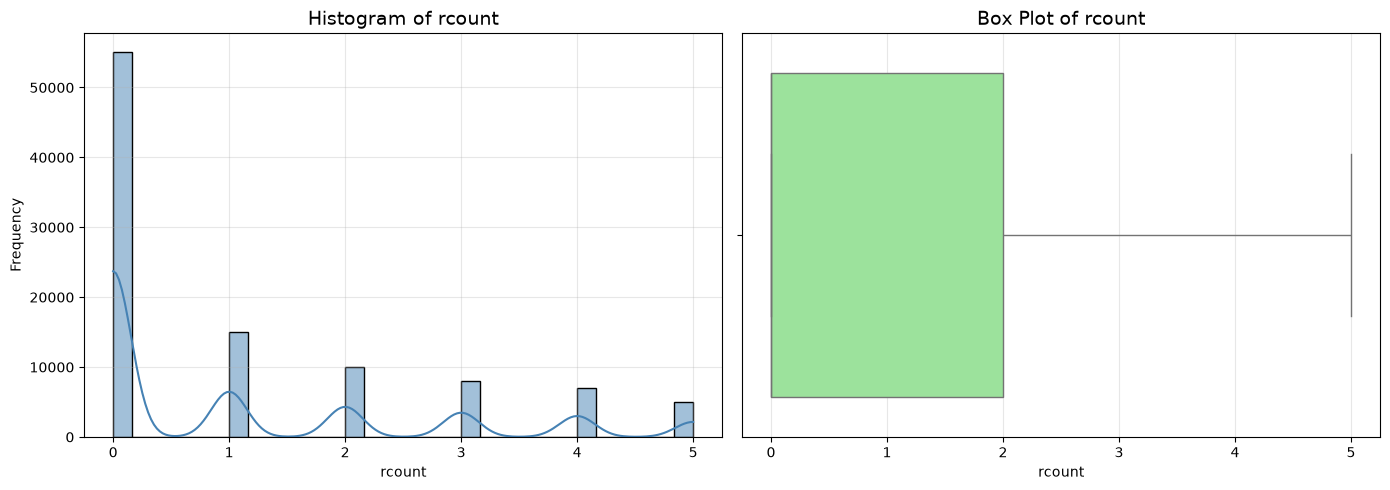


Summary Statistics for rcount
Mean      : 1.12
Median    : 0.00
Mode      : 0.00
Minimum   : 0.00
Maximum   : 5.00
Std Dev   : 1.54
Skewness  : 1.20


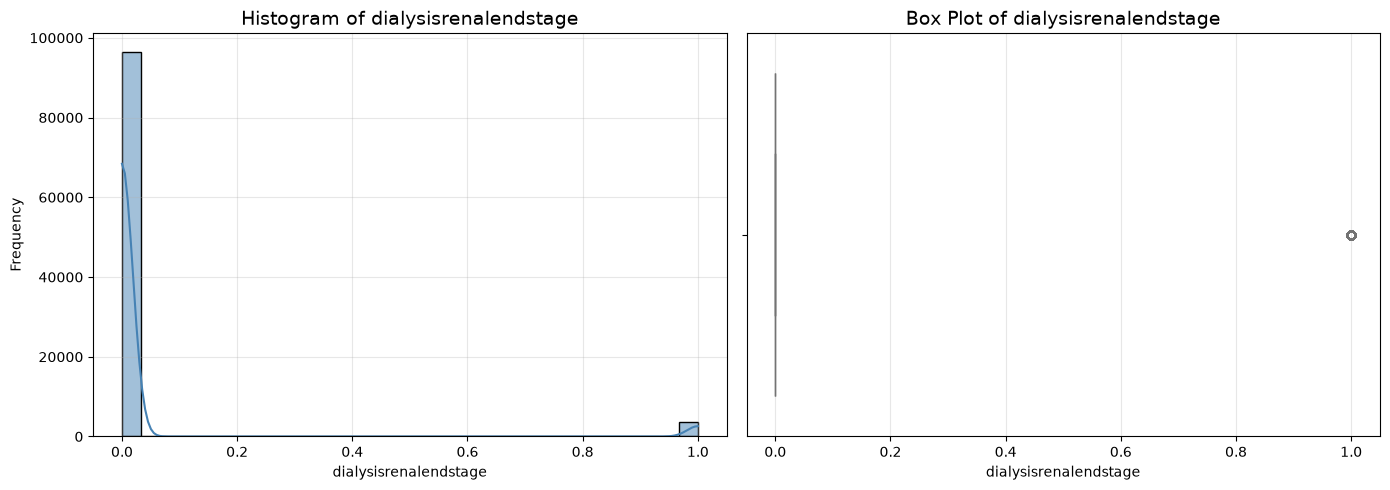


Summary Statistics for dialysisrenalendstage
Mean      : 0.04
Median    : 0.00
Mode      : 0.00
Minimum   : 0.00
Maximum   : 1.00
Std Dev   : 0.19
Skewness  : 4.95


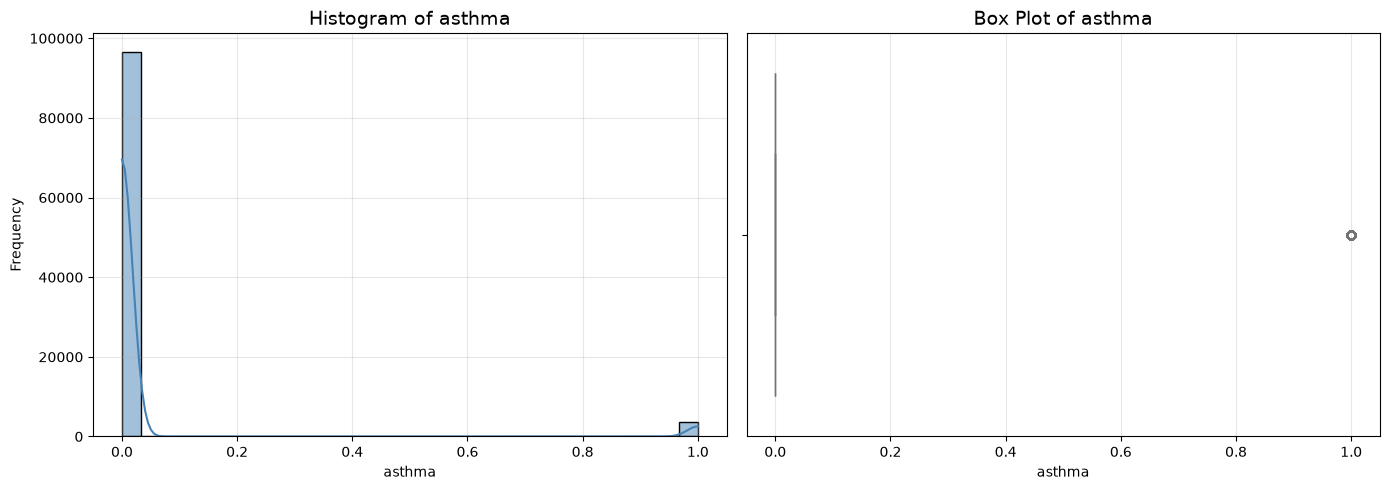


Summary Statistics for asthma
Mean      : 0.04
Median    : 0.00
Mode      : 0.00
Minimum   : 0.00
Maximum   : 1.00
Std Dev   : 0.18
Skewness  : 5.04


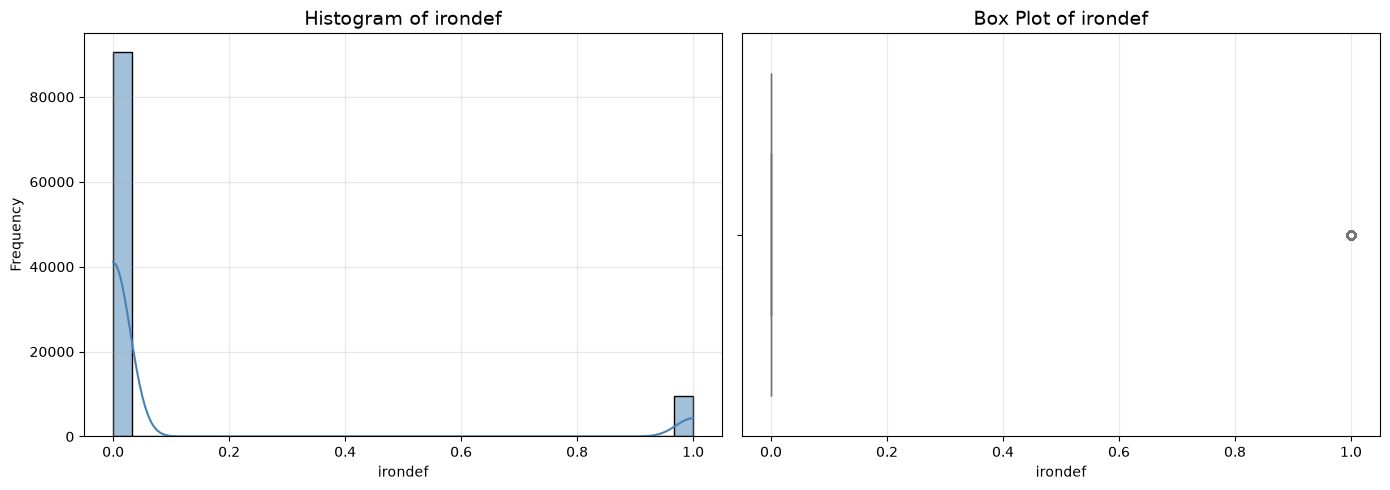


Summary Statistics for irondef
Mean      : 0.09
Median    : 0.00
Mode      : 0.00
Minimum   : 0.00
Maximum   : 1.00
Std Dev   : 0.29
Skewness  : 2.76


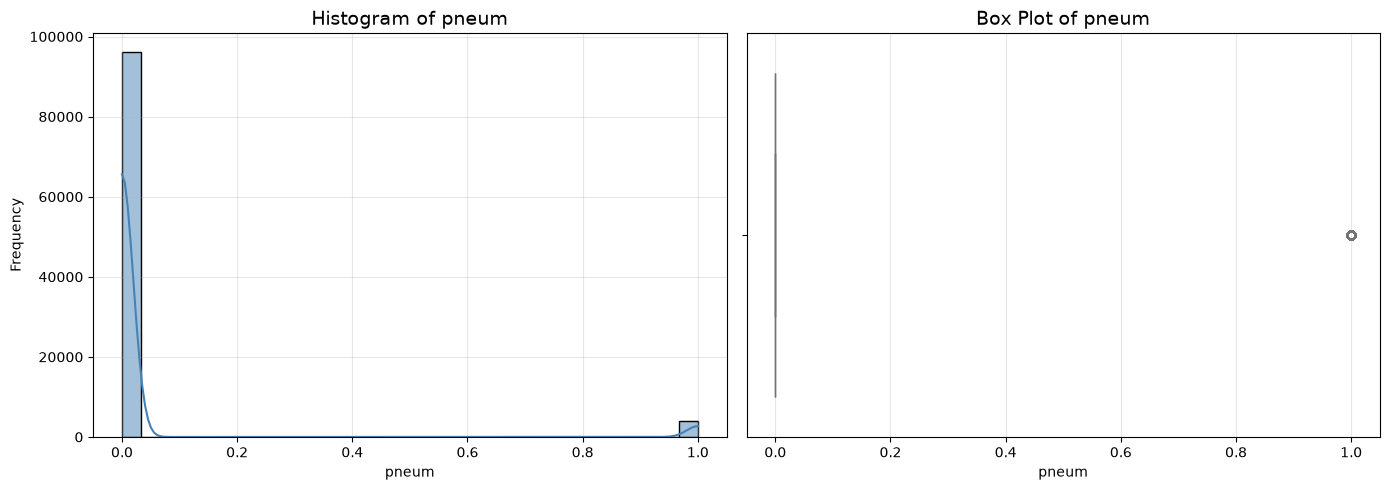


Summary Statistics for pneum
Mean      : 0.04
Median    : 0.00
Mode      : 0.00
Minimum   : 0.00
Maximum   : 1.00
Std Dev   : 0.19
Skewness  : 4.73


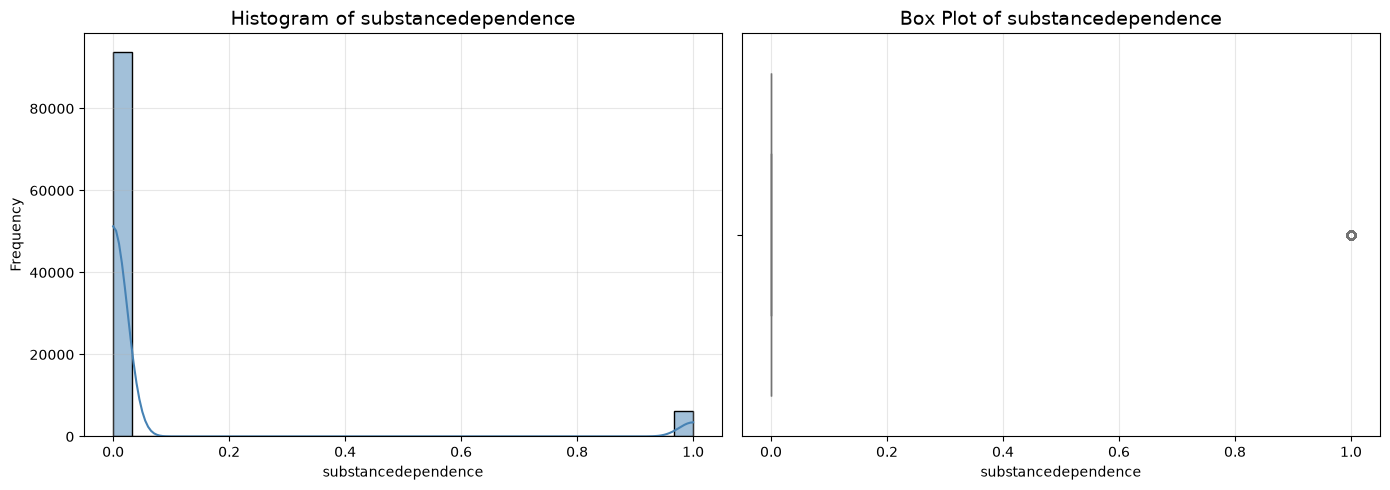


Summary Statistics for substancedependence
Mean      : 0.06
Median    : 0.00
Mode      : 0.00
Minimum   : 0.00
Maximum   : 1.00
Std Dev   : 0.24
Skewness  : 3.60


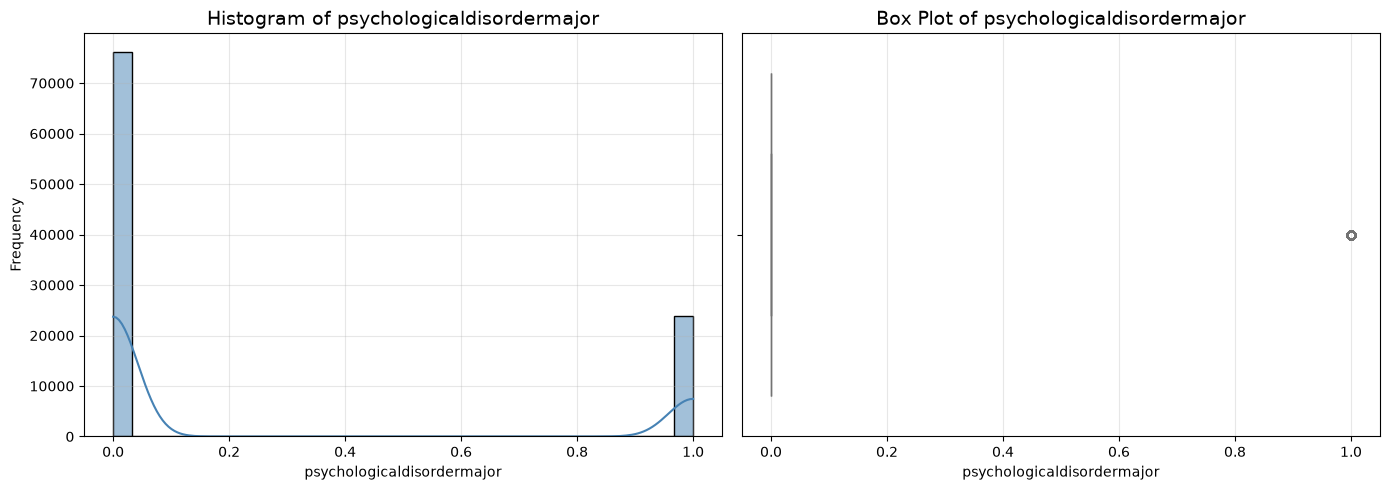


Summary Statistics for psychologicaldisordermajor
Mean      : 0.24
Median    : 0.00
Mode      : 0.00
Minimum   : 0.00
Maximum   : 1.00
Std Dev   : 0.43
Skewness  : 1.22


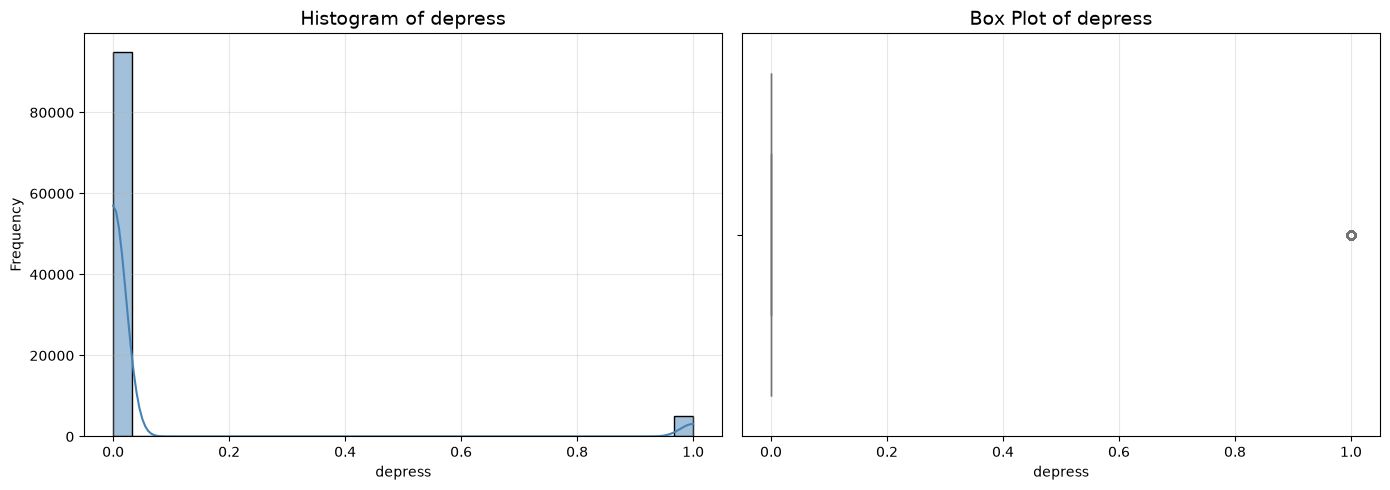


Summary Statistics for depress
Mean      : 0.05
Median    : 0.00
Mode      : 0.00
Minimum   : 0.00
Maximum   : 1.00
Std Dev   : 0.22
Skewness  : 4.05


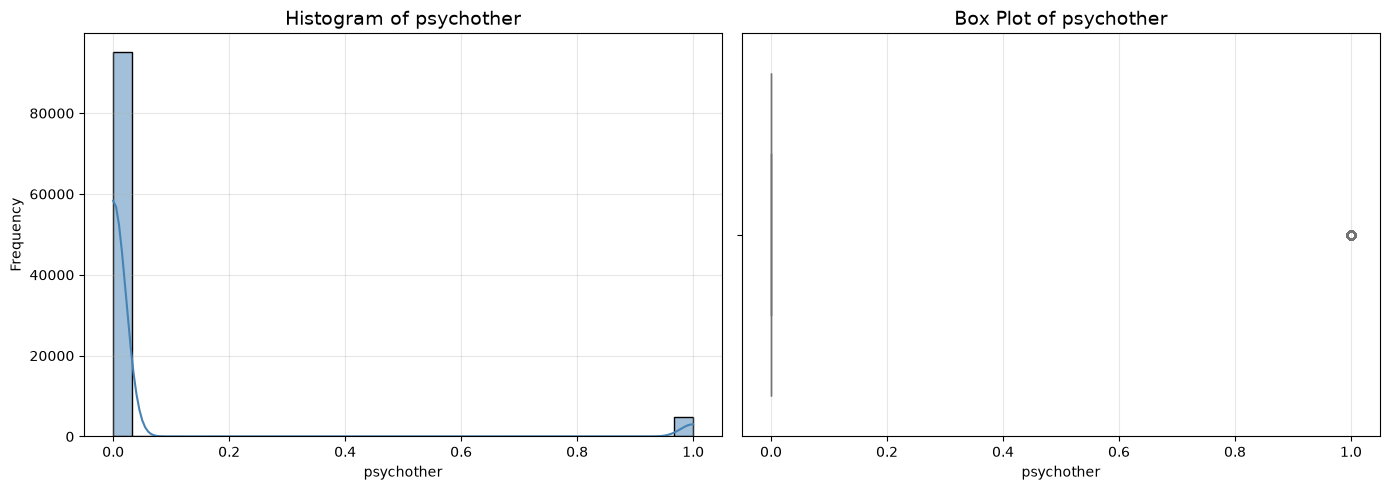


Summary Statistics for psychother
Mean      : 0.05
Median    : 0.00
Mode      : 0.00
Minimum   : 0.00
Maximum   : 1.00
Std Dev   : 0.22
Skewness  : 4.16


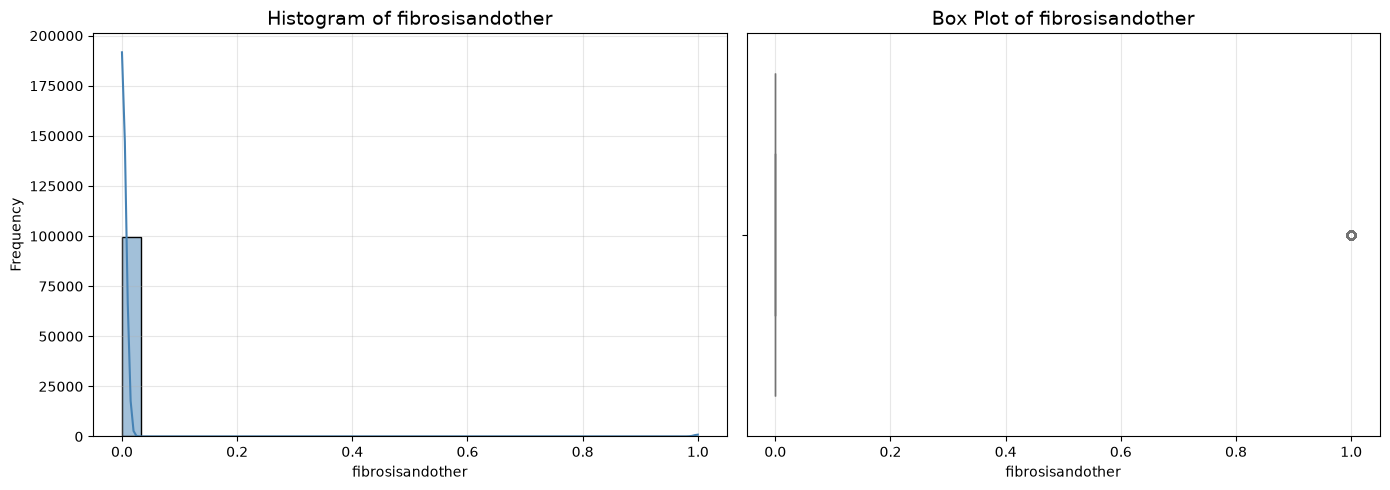


Summary Statistics for fibrosisandother
Mean      : 0.00
Median    : 0.00
Mode      : 0.00
Minimum   : 0.00
Maximum   : 1.00
Std Dev   : 0.07
Skewness  : 14.35


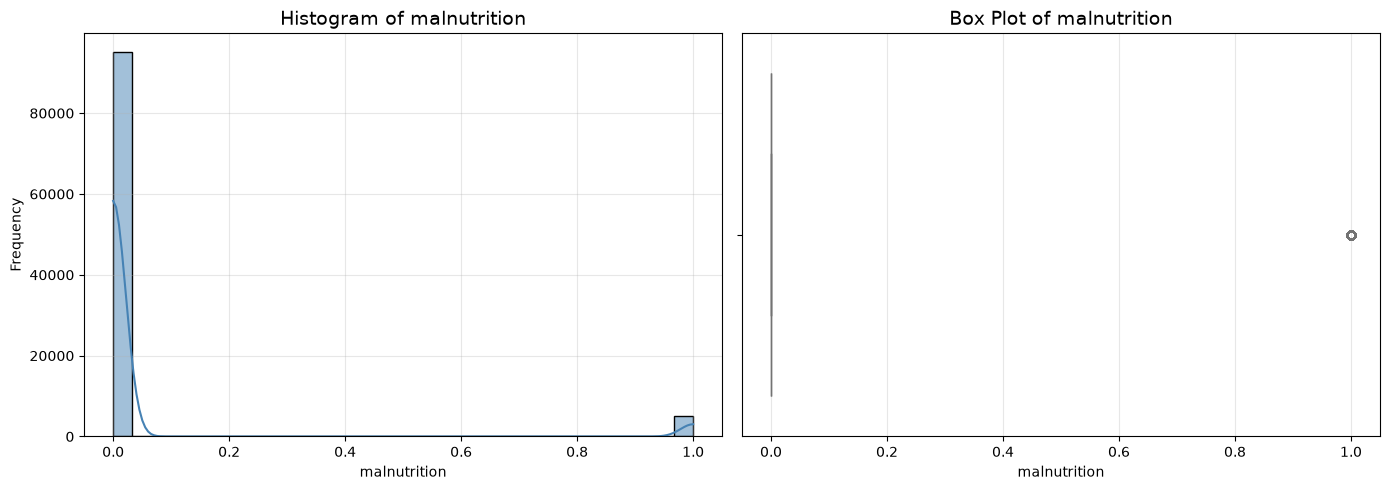


Summary Statistics for malnutrition
Mean      : 0.05
Median    : 0.00
Mode      : 0.00
Minimum   : 0.00
Maximum   : 1.00
Std Dev   : 0.22
Skewness  : 4.15


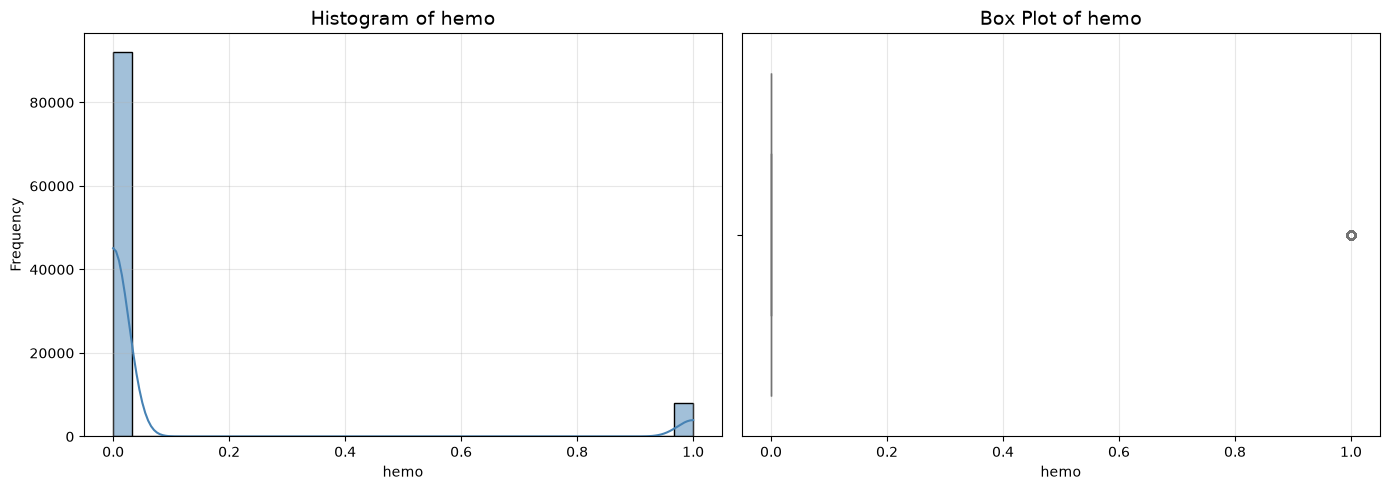


Summary Statistics for hemo
Mean      : 0.08
Median    : 0.00
Mode      : 0.00
Minimum   : 0.00
Maximum   : 1.00
Std Dev   : 0.27
Skewness  : 3.10


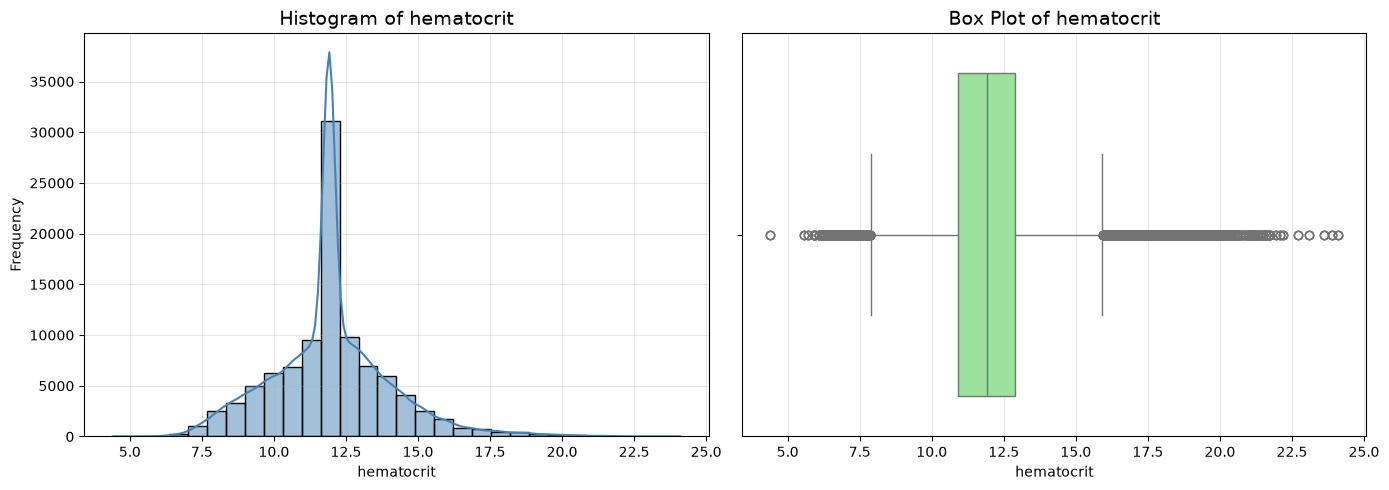


Summary Statistics for hematocrit
Mean      : 11.98
Median    : 11.90
Mode      : 11.90
Minimum   : 4.40
Maximum   : 24.10
Std Dev   : 2.03
Skewness  : 0.56


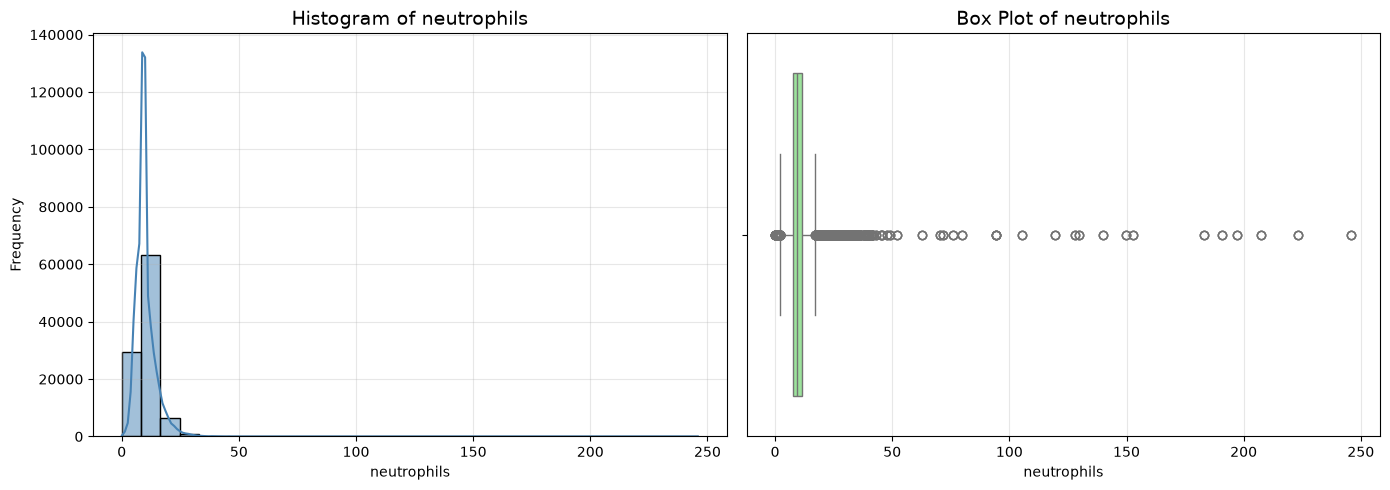


Summary Statistics for neutrophils
Mean      : 10.18
Median    : 9.40
Mode      : 9.40
Minimum   : 0.10
Maximum   : 245.90
Std Dev   : 5.35
Skewness  : 13.28


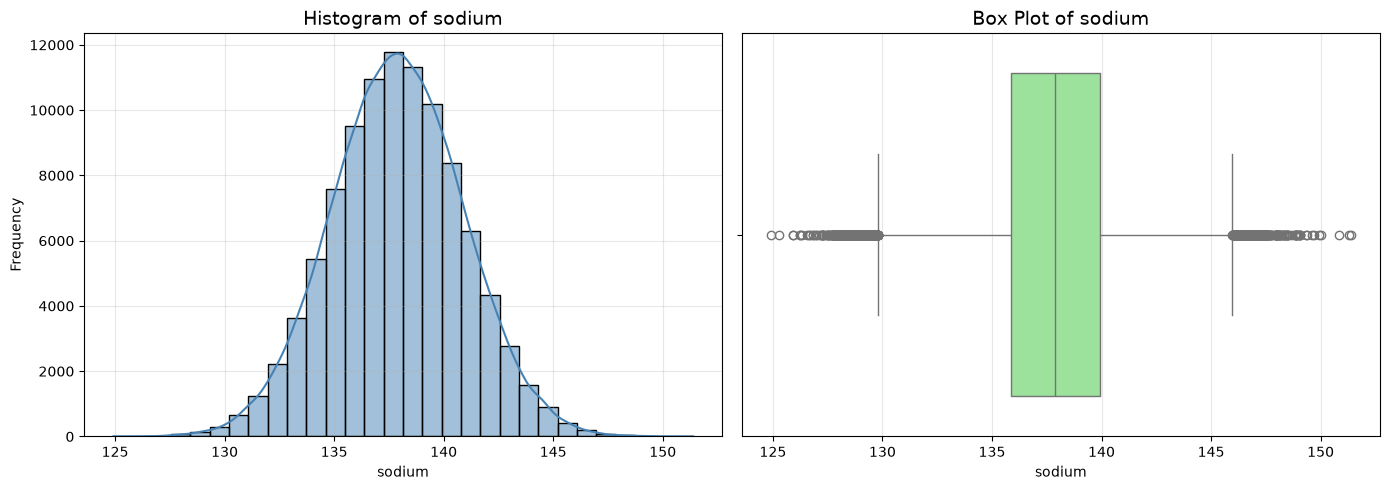


Summary Statistics for sodium
Mean      : 137.89
Median    : 137.89
Mode      : 133.82
Minimum   : 124.91
Maximum   : 151.39
Std Dev   : 3.00
Skewness  : 0.00


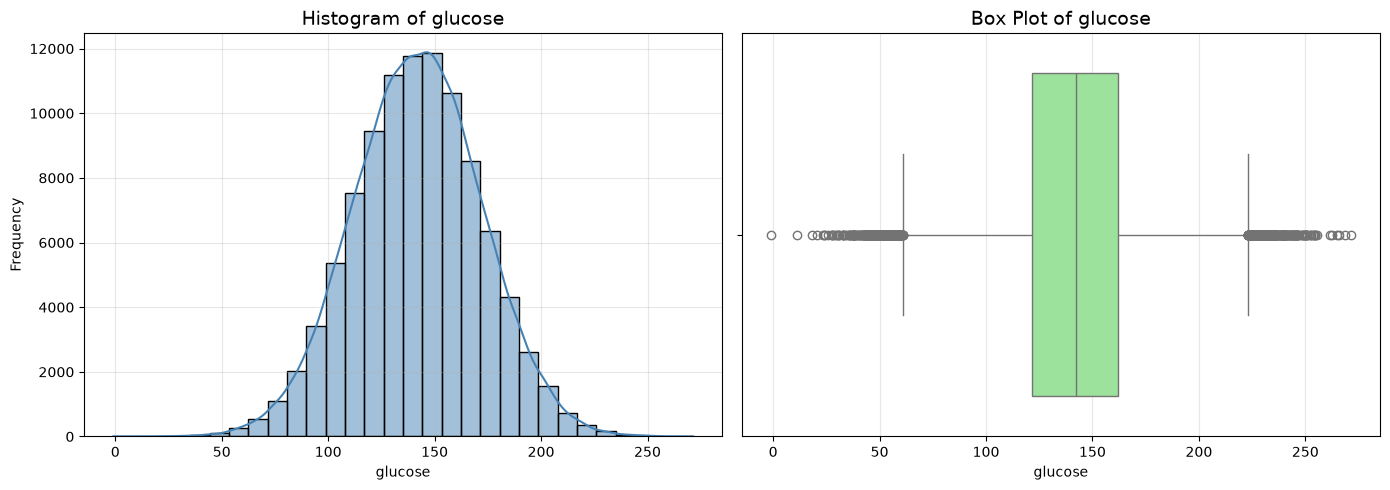


Summary Statistics for glucose
Mean      : 141.96
Median    : 142.09
Mode      : 129.72
Minimum   : -1.01
Maximum   : 271.44
Std Dev   : 29.99
Skewness  : -0.01


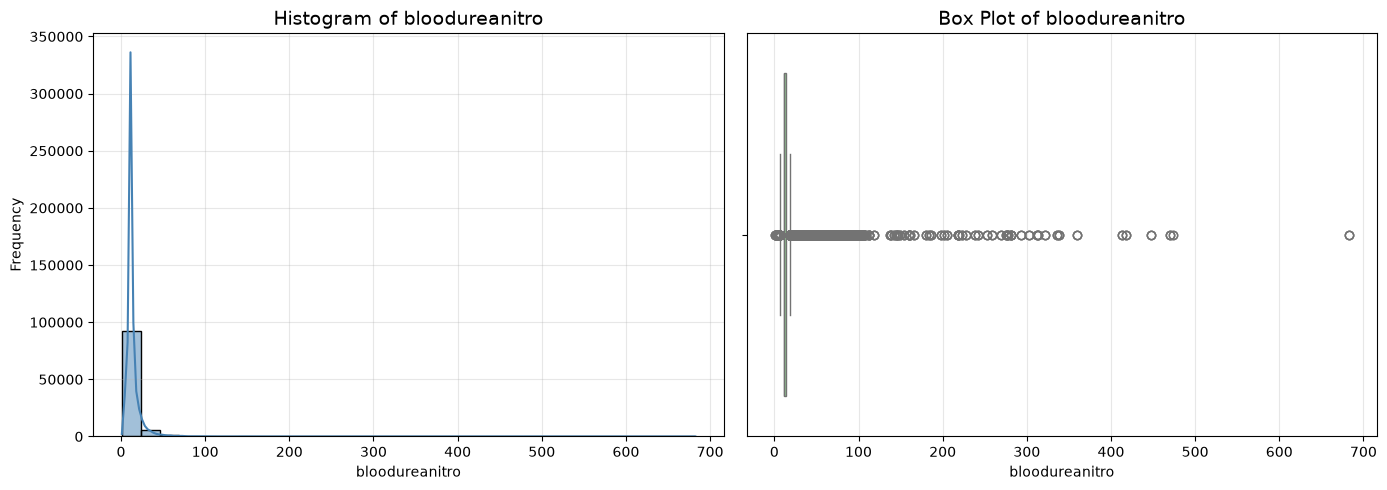


Summary Statistics for bloodureanitro
Mean      : 14.10
Median    : 12.00
Mode      : 12.00
Minimum   : 1.00
Maximum   : 682.50
Std Dev   : 12.95
Skewness  : 17.29


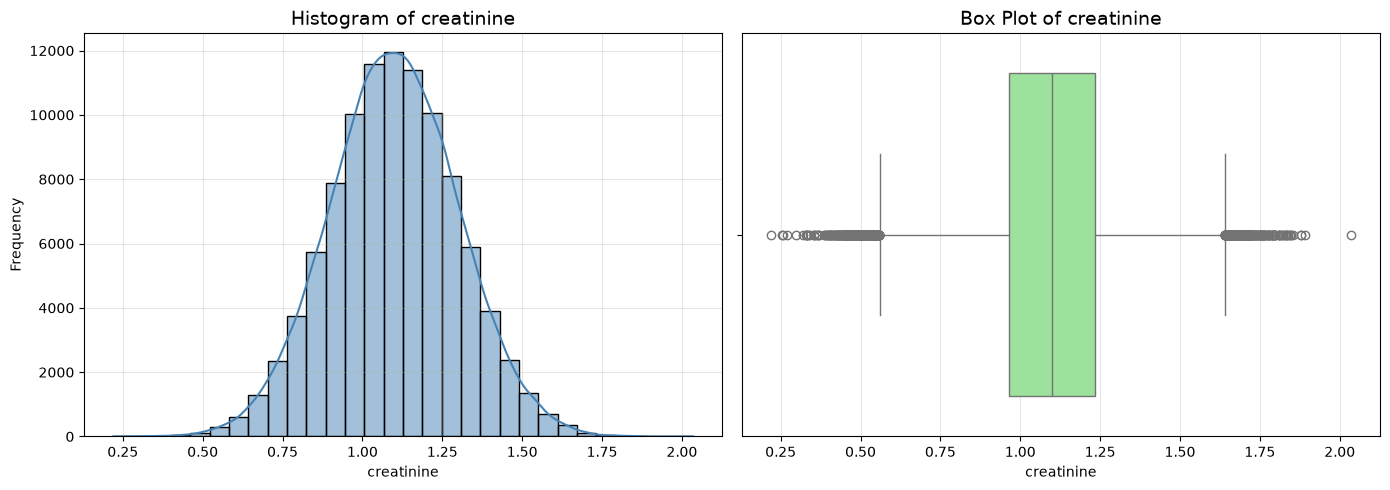


Summary Statistics for creatinine
Mean      : 1.10
Median    : 1.10
Mode      : 0.90
Minimum   : 0.22
Maximum   : 2.04
Std Dev   : 0.20
Skewness  : 0.00


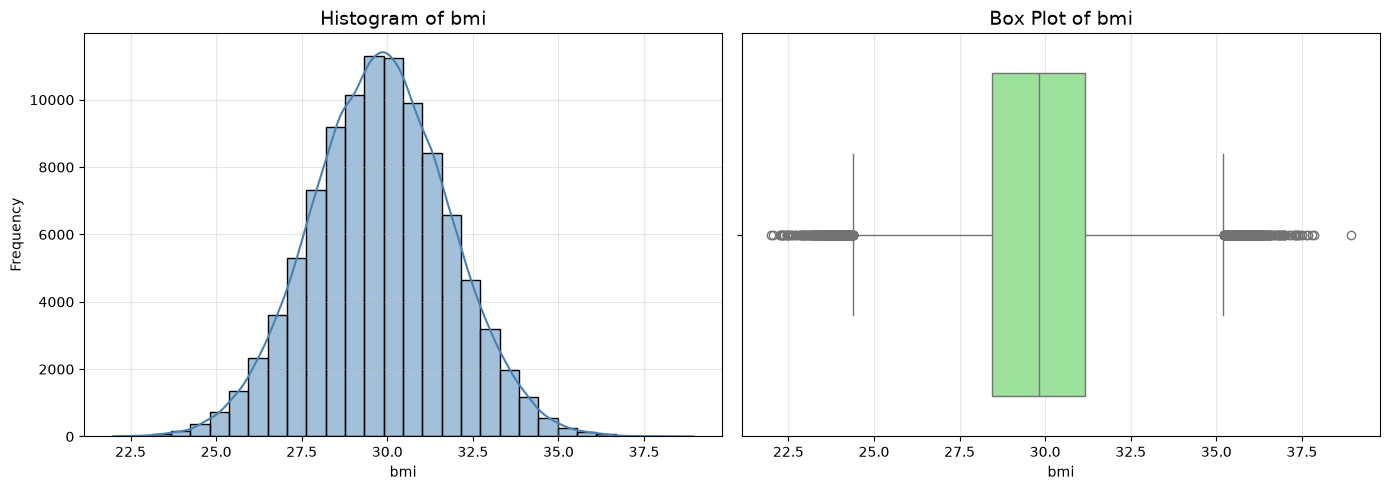


Summary Statistics for bmi
Mean      : 29.81
Median    : 29.81
Mode      : 27.84
Minimum   : 21.99
Maximum   : 38.94
Std Dev   : 2.00
Skewness  : 0.01


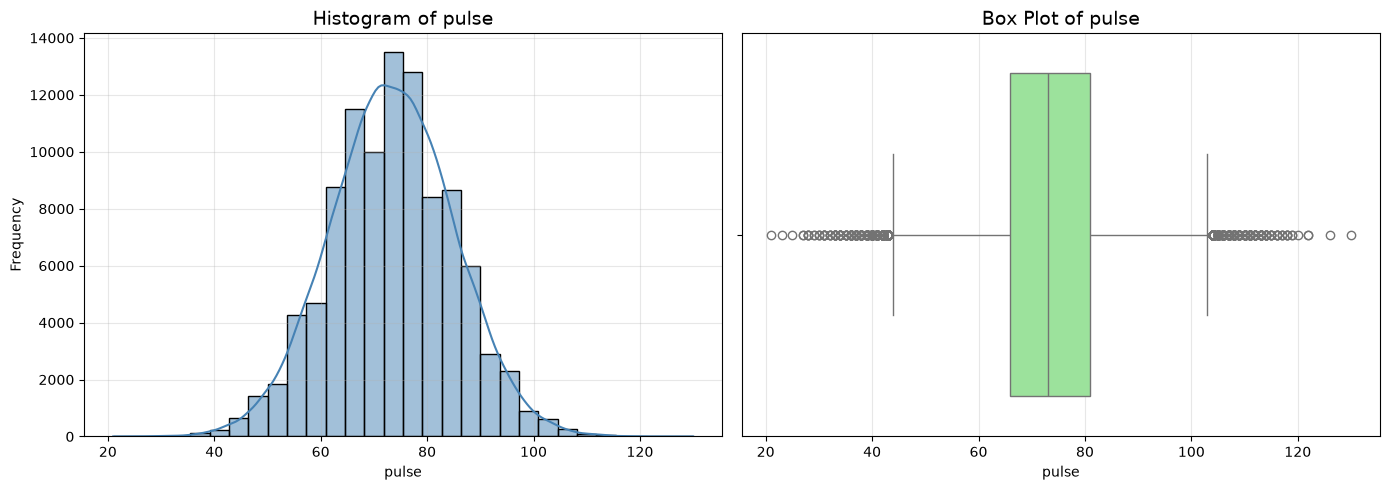


Summary Statistics for pulse
Mean      : 73.44
Median    : 73.00
Mode      : 71.00
Minimum   : 21.00
Maximum   : 130.00
Std Dev   : 11.64
Skewness  : 0.00


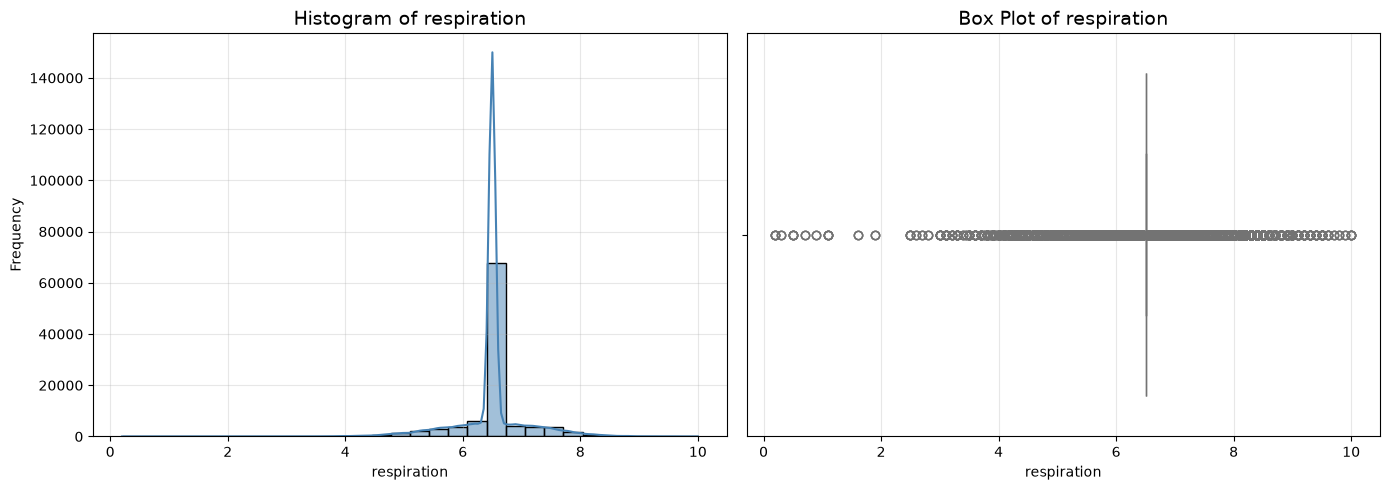


Summary Statistics for respiration
Mean      : 6.49
Median    : 6.50
Mode      : 6.50
Minimum   : 0.20
Maximum   : 10.00
Std Dev   : 0.57
Skewness  : -0.55


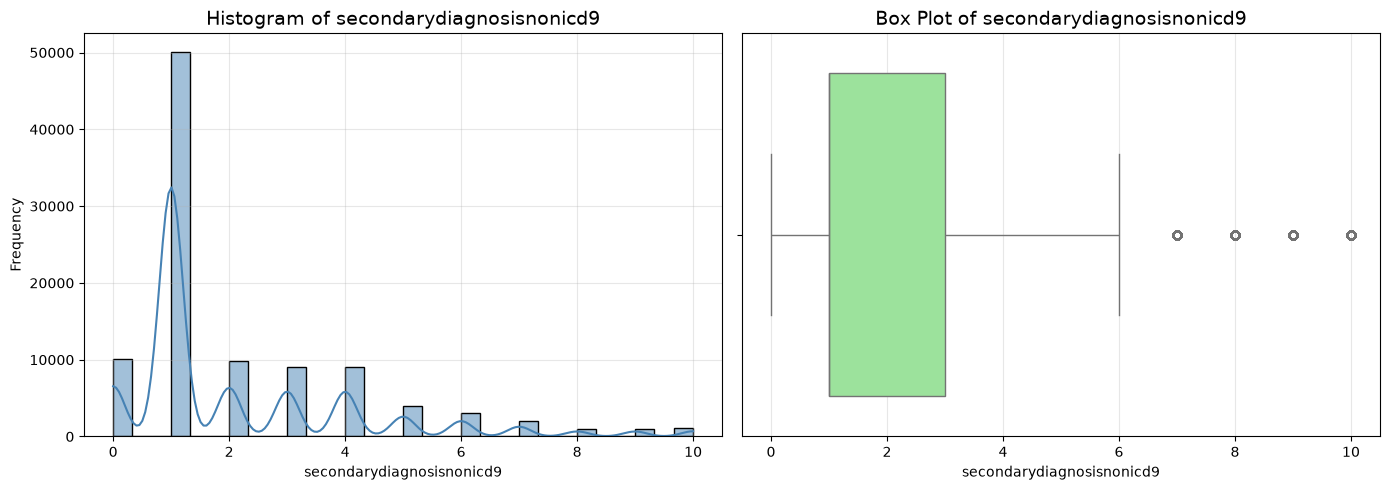


Summary Statistics for secondarydiagnosisnonicd9
Mean      : 2.12
Median    : 1.00
Mode      : 1.00
Minimum   : 0.00
Maximum   : 10.00
Std Dev   : 2.05
Skewness  : 1.67


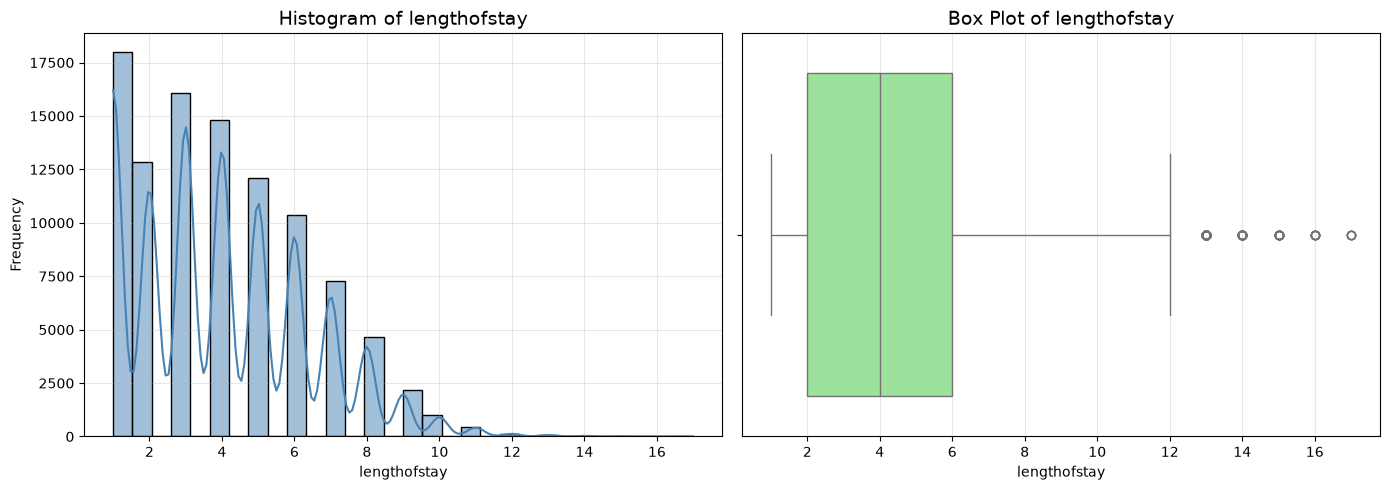


Summary Statistics for lengthofstay
Mean      : 4.00
Median    : 4.00
Mode      : 1.00
Minimum   : 1.00
Maximum   : 17.00
Std Dev   : 2.36
Skewness  : 0.63


In [55]:
for col in plot_numeric_features:
    plt.figure(figsize=(14,5))

    # Histogram + KDE
    plt.subplot(1,2,1)
    sns.histplot(df[col], kde=True, bins=30, color='steelblue')
    plt.title(f'Histogram of {col}', fontsize=14)
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.grid(alpha=0.3)

    # Box Plot
    plt.subplot(1,2,2)
    sns.boxplot(x=df[col], color='lightgreen')
    plt.title(f'Box Plot of {col}', fontsize=14)
    plt.xlabel(col)
    plt.grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Summary Statistics
    print(f"\n{'='*60}")
    print(f"Summary Statistics for {col}")
    print(f"{'='*60}")
    print(f"Mean      : {df[col].mean():.2f}")
    print(f"Median    : {df[col].median():.2f}")
    print(f"Mode      : {df[col].mode()[0]:.2f}")
    print(f"Minimum   : {df[col].min():.2f}")
    print(f"Maximum   : {df[col].max():.2f}")
    print(f"Std Dev   : {df[col].std():.2f}")
    print(f"Skewness  : {df[col].skew():.2f}")

**Rule of Thumb**

|Skewness| < 0.5 → Approximately symmetric (few/no outliers)

0.5 ≤ |Skewness| < 1 → Slightly skewed (possible mild outliers)

1 ≤ |Skewness| < 2 → Moderately skewed (likely outliers)


|Skewness| ≥ 2 → Highly skewed (strong evidence of outliers)

**Important Note About Binary Variables (0/1)**



Features such as:

dialysisrenalendstage

asthma

irondef

pneum

substancedependence

depress

psychother

fibrosisandother

malnutrition

hemo

psychologicaldisordermajor

are binary variables (0/1).

Their high skewness is expected because the "1" class is rare. These are **not true outliers** in the statistical sense. Do not remove or cap values in these variables. Treat them as categorical/binary features.

**the strongest evidence of genuine outliers is in:**

bloodureanitro

neutrophils

secondarydiagnosisnonicd9

rcount 

hematocrit

respiration

| Feature                       | Statistically an Outlier? | Clinically Genuine? | IQR Treatment? |
| ----------------------------- | :-----------------------: | :-----------------: | :------------: |
| **bloodureanitro**            |           ✅ Yes           |        ✅ Yes        |   ✅ Yes            |
| **neutrophils**               |           ✅ Yes           |        ✅ Yes        |      ✅ Yes       |
| **secondarydiagnosisnonicd9** |           ✅ Yes           |        ✅ Yes        |       ✅ Yes    |
| **rcount**                    |           ✅ Yes           |        ✅ Yes        |       ✅ Yes    |
| **hematocrit**                |            Mild           |        ✅ Yes        |       ✅ Yes       |
| **respiration**               |            Mild           |        ✅ Yes        |       ✅ Yes     |


**I'm not applying outliers treatment because  with one important distinction between statistical outliers and clinically meaningful values.**

In [56]:
df.head()

,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,2012-08-29,0,F,0,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,2012-09-01,B,3
1,2012-05-26,5,F,0,0,0,0,0,0,0,...,94.078507,8.0,0.943164,28.460516,61,6.5,1,2012-06-02,A,7
2,2012-09-22,1,F,0,0,0,0,0,0,0,...,130.530524,12.0,1.065750,28.843812,64,6.5,2,2012-09-25,B,3
3,2012-08-09,0,F,0,0,0,0,0,0,0,...,163.377028,12.0,0.906862,27.959007,76,6.5,1,2012-08-10,A,1
4,2012-12-20,0,F,0,0,0,1,0,1,0,...,94.886654,11.5,1.242854,30.258927,67,5.6,2,2012-12-24,E,4


In [57]:
df_iqr=df[["bloodureanitro","neutrophils","secondarydiagnosisnonicd9","rcount","hematocrit","respiration"]]

for col in df_iqr:
    

SyntaxError: incomplete input (2811034172.py, line 4)

In [ ]:
# if outliers existed



for col in df_iqr:

    Q1 = df_iqr[col].quantile(0.25)
    Q3 = df_iqr[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print(f"\n{col}")
    print("-"*40)
    print(f"Q1          : {Q1:.2f}")
    print(f"Q3          : {Q3:.2f}")
    print(f"IQR         : {IQR:.2f}")
    print(f"Lower Bound : {lower:.2f}")
    print(f"Upper Bound : {upper:.2f}")

    # Cap the outliers
    df_iqr[col] = df_iqr[col].clip(lower=lower, upper=upper)


bloodureanitro
----------------------------------------
Q1          : 11.00
Q3          : 14.00
IQR         : 3.00
Lower Bound : 6.50
Upper Bound : 18.50

neutrophils
----------------------------------------
Q1          : 7.70
Q3          : 11.50
IQR         : 3.80
Lower Bound : 2.00
Upper Bound : 17.20

secondarydiagnosisnonicd9
----------------------------------------
Q1          : 1.00
Q3          : 3.00
IQR         : 2.00
Lower Bound : -2.00
Upper Bound : 6.00

rcount
----------------------------------------
Q1          : 0.00
Q3          : 2.00
IQR         : 2.00
Lower Bound : -3.00
Upper Bound : 5.00

hematocrit
----------------------------------------
Q1          : 10.90
Q3          : 12.90
IQR         : 2.00
Lower Bound : 7.90
Upper Bound : 15.90

respiration
----------------------------------------
Q1          : 6.50
Q3          : 6.50
IQR         : 0.00
Lower Bound : 6.50
Upper Bound : 6.50


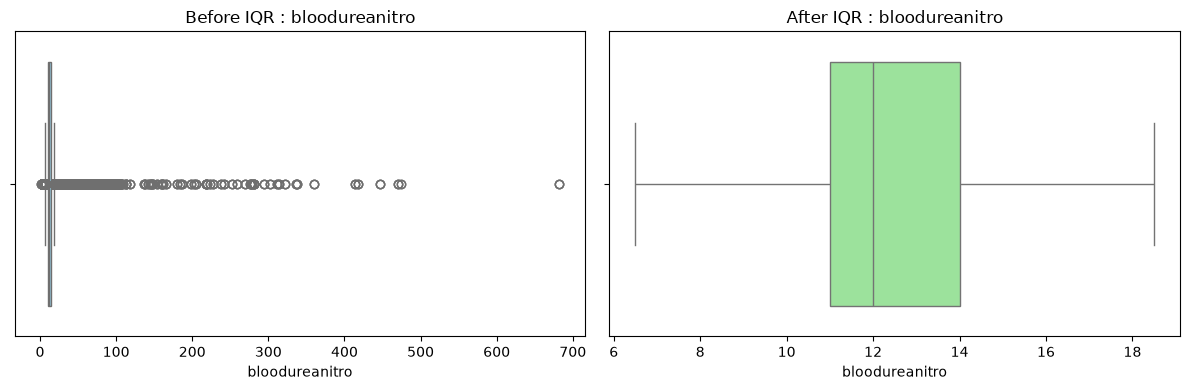

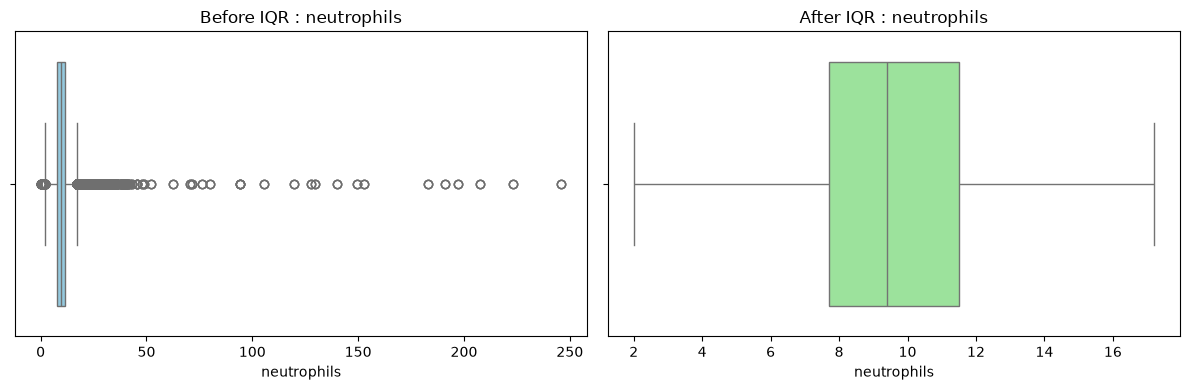

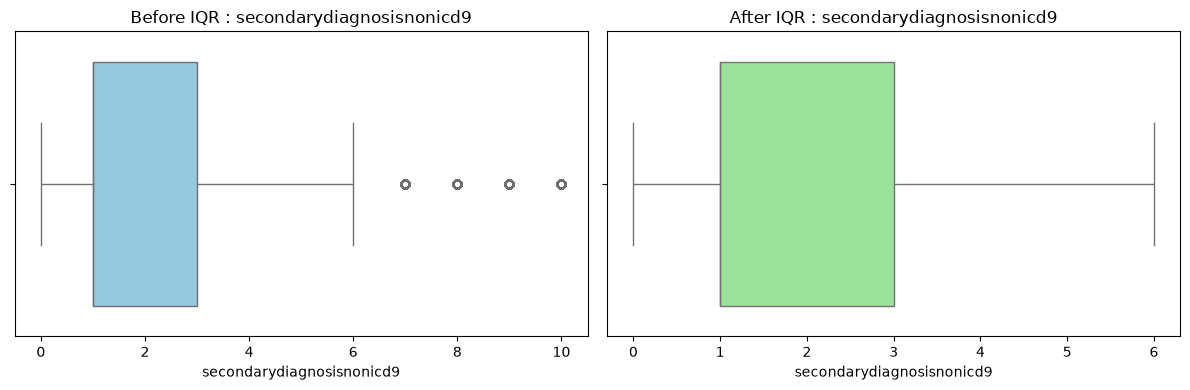

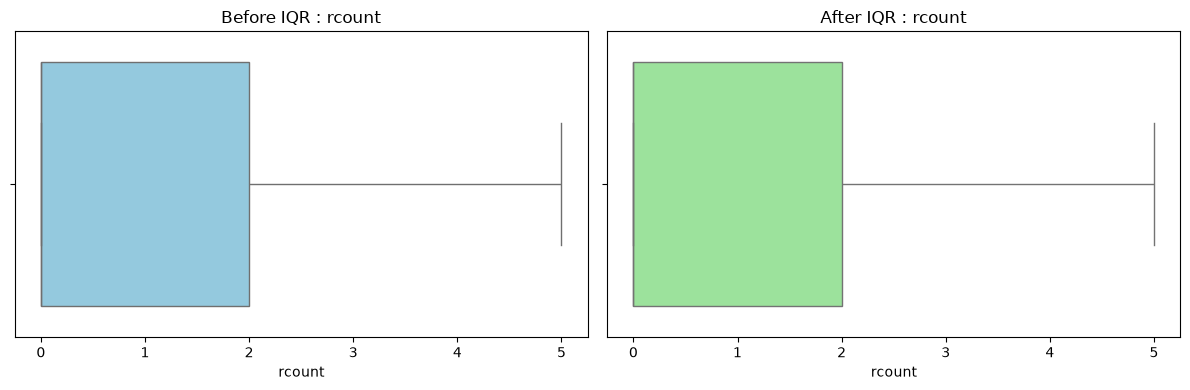

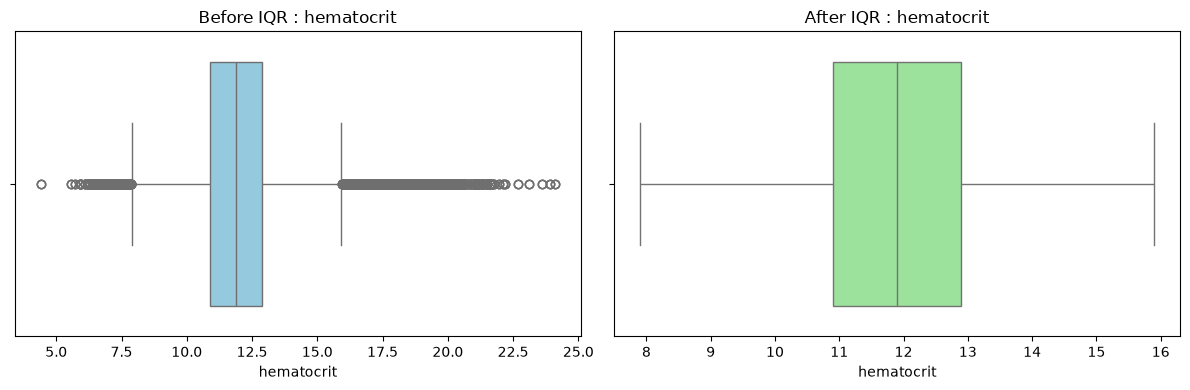

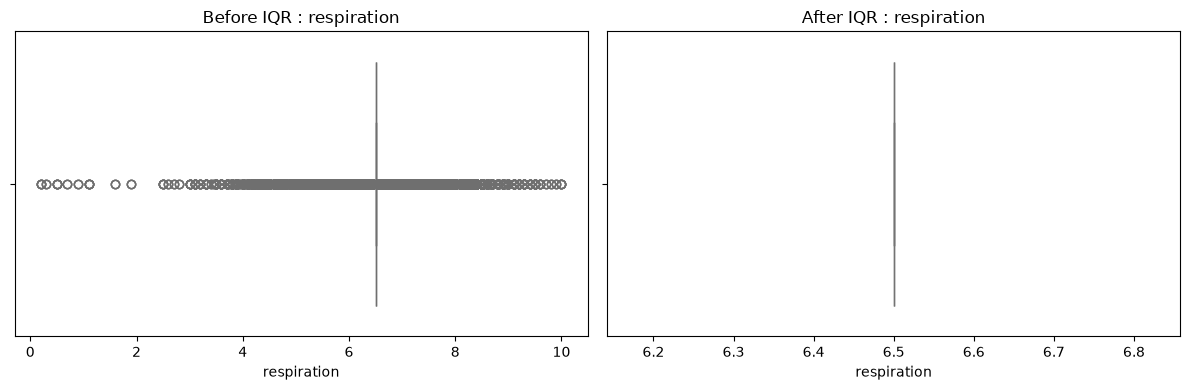

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in df_iqr:

    plt.figure(figsize=(12,4))

    plt.subplot(1,2,1)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Before IQR : {col}')

    plt.subplot(1,2,2)
    sns.boxplot(x=df_iqr[col], color='lightgreen')
    plt.title(f'After IQR : {col}')

    plt.tight_layout()
    plt.show()

**+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++**

# 4. Feature Engneering

- **1.feature selection**

# 4. Feature Engneering



feature engineering is the process of selecting, creating, transforming, and extracting variables from raw data to help machine learning models learn patterns and make better predictions

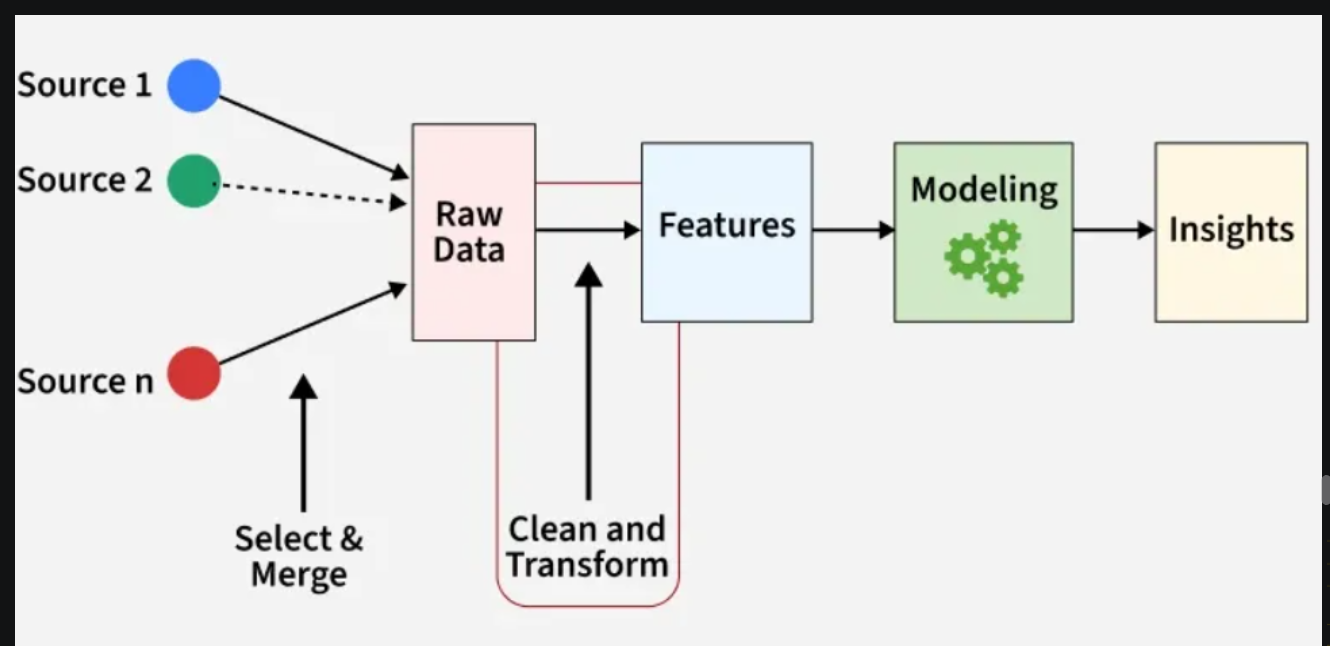

- **1.feature selection**
the process of choosing the most relevant and useful variables (features) from your raw dataset to use in a machine learning model

 Feature selection involves choosing a subset of relevant features to use:

Filter methods: Based on statistical measures like correlation.  this was most popular

Wrapper methods: Select based on model performance.

Embedded methods: Feature selection integrated within model training.

- **Numerical_features selection**

from The correlation or HEAP MAP model, we can see that the correlation between independent variables and dependent variables but some independent variables are correlated with another independent variables

**what is VIF ?**

Variance inflation factor (VIF) can be used for feature selection in machine learning analysis.

VIF starts at 1 and has no upper limit

**VIF = 1, no correlation between the independent variable and the other variables**

**VIF exceeding 5 or 10 indicates high multicollinearity between this independent variable and the others**

In [59]:
# Import library for VIF
%pip install statsmodels

from statsmodels.stats.outliers_influence import variance_inflation_factor

def calc_vif(X):
    vif = pd.DataFrame()
    vif["variables"] = X.columns
    vif["VIF"] = [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
    return vif

def calc_vif(X):

    # Calculating VIF
    vif = pd.DataFrame()
    vif["variables"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    return(vif)

  Using cached statsmodels-0.15.0-cp312-cp312-win_amd64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
Using cached statsmodels-0.15.0-cp312-cp312-win_amd64.whl (11.3 MB)
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)

   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   ---------------- ----------------------- 2/5 [interface-meta]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ---------

In [61]:
df.head(1)

,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,2012-08-29,0,F,0,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,2012-09-01,B,3


In [60]:
calc_vif(df[[i for i in plot_numeric_features if i not in ['lengthofstay']]])

,variables,VIF
0,rcount,1.000212
1,dialysisrenalendstage,1.185972
2,asthma,1.006929
3,irondef,1.149262
4,pneum,1.056450
5,substancedependence,1.035299
6,psychologicaldisordermajor,1.161091
7,depress,1.099445
8,psychother,1.300164
9,fibrosisandother,1.042331


# what is the process if vif value more than 5



<!--  -->

In [ ]:



# or 

# calc_vif(  df[[i for i in plot_numeric_features if i not in ['lengthofstay',"bmi"]]]   )

# again i have to calculate  remaniing values

# calc_vif(  df[[i for i in plot_numeric_features if i not in ['lengthofstay',"bmi","sodium"]]]   )

# calc_vif(  df[[i for i in plot_numeric_features if i not in ['lengthofstay',"bmi","sodium","irondef"]]]   )

# Dropping multi-colinear variables

In [64]:
#df.drop(columns=["sodium","bmi","respiration","hematocrit","pulse","creatinine","glucose"],axis=1,inplace=True)

In [ ]:
df.head(1)

,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,psychother,fibrosisandother,malnutrition,hemo,neutrophils,bloodureanitro,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,2012-08-29,0,F,0,0,0,0,0,0,0,0,0,0,0,14.2,12.0,4,2012-09-01,B,3


# Categorical features

**Check Multicollinearity for Categorical features**  (this can use if target variable also categorical otherwise use ANOVA test)

**A chi-squared test (also chi-square or χ2 test) is a statistical hypothesis test that is valid to perform when the test statistic is chi-squared distributed under the null hypothesis, specifically Pearson's chi-squared test**


- A chi-square statistic is one way to show a relationship between two categorical variables.



Here we test correlation of Categorical columns with Target column


- Null Hypothesis (
):
The Feature is independent of target column (No-Correlation)


- Alternative Hypothesis (
):
The Feature and Target column are not independent (Correalted)

In [66]:
from scipy.stats import chi2_contingency
chi2_test = []
for feature in categorical_features:
    if chi2_contingency(pd.crosstab(df['lengthofstay'], df[feature]))[1] < 0.05:
        chi2_test.append('Reject Null Hypothesis')
    else:
        chi2_test.append('Fail to Reject Null Hypothesis')
result = pd.DataFrame(data=[categorical_features, chi2_test]).T
result.columns = ['Column', 'Hypothesis Result']
result

,Column,Hypothesis Result
0,gender,Reject Null Hypothesis
1,facid,Reject Null Hypothesis


**ANOVA test**

the decision rule is based on the p-value and the chosen significance level (α), which is typically 0.05.





Hypotheses

For each categorical feature:

**Null Hypothesis (H0)** :
 The mean Length of Stay is the same across all categories of the feature.



**Alternative Hypothesis (H1)**:
At least one category has a different mean Length of Stay.
Decision Rule

Let α = 0.05.

**If p-value < 0.05**
- Reject the Null Hypothesis (H0)

Conclude that the categorical feature has a statistically significant relationship with lengthofstay.

**If p-value ≥ 0.05**
- Fail to Reject the Null Hypothesis (H0)

Conclude that there is no statistically significant evidence that the feature affects lengthofstay.



Decision Rule Table
P-Value	Decision	Conclusion

**< 0.05	Reject H0**
	​

	Feature is statistically significant. Mean Length of Stay differs across categories.

**≥ 0.05	Fail to Reject H0**
	​

	Feature is not statistically significant. Mean Length of Stay does not differ significantly across categories.

**Decision Rule:**

 At a significance level of 5% (α = 0.05), if the p-value is less than 0.05, reject the null hypothesis and conclude that the categorical feature has a statistically significant effect on the Length of Stay. Otherwise, fail to reject the null hypothesis and conclude that there is no statistically significant evidence that the feature affects the Length of Stay.

**When can you drop it?**

You can consider dropping the feature if all of the following are true:

✅ ANOVA p-value ≥ 0.05

✅ The feature has no practical or domain importance.

✅ Feature importance from models (e.g., Random Forest, XGBoost) is also very low.

✅ Correlation with other variables is weak.

✅ Cross-validation performance does not decrease after removing it.
When should you keep it?

**when to Keep the feature:         if**

It is clinically or medically important.

It is known from domain knowledge to influence Length of Stay.

Tree-based models assign it high importance.

It improves model performance during feature selection.

#For Example

| Feature        | P-value  | ANOVA Decision    | Drop?                        |
| -------------- | -------- | ----------------- | ---------------------------- |
| gender         | 0.62     | Fail to Reject H₀ | Maybe                        |
| admission_type | 0.0001   | Reject H₀         | Keep                         |
| age_group      | 0.12     | Fail to Reject H₀ | Check model importance first |
| severity       | 0.000001 | Reject H₀         | Keep                         |


**Notice that age_group has p = 0.12. I wouldn't drop it immediately because age is often clinically important. I'd first check whether it improves predictive performance.**

In [ ]:
from scipy.stats import f_oneway

anova_result = []

for feature in categorical_features:

    groups = [group['lengthofstay'].dropna()
              for _, group in df.groupby(feature)]

    if len(groups) > 1:

        f_stat, p_value = f_oneway(*groups)

        if p_value < 0.05:
            decision = "Reject H₀ (Significant)"
            keep_drop = "Keep"
        else:
            decision = "Fail to Reject H₀ (Not Significant)"
            keep_drop = "Check / Maybe Drop"

        anova_result.append([
            feature,
            round(f_stat, 2),
            round(p_value, 5),   # Displays 0.00000 instead of scientific notation
            decision,
            keep_drop
        ])

anova_df = pd.DataFrame(
    anova_result,
    columns=[
        'Feature',
        'F-Statistic',
        'P-Value',
        'Decision',
        'Recommendation'
    ]
)

anova_df.sort_values('P-Value')

,Feature,F-Statistic,P-Value,Decision,Recommendation
0,gender,486.41,0.0,Reject H₀ (Significant),Keep
1,facid,4153.34,0.0,Reject H₀ (Significant),Keep


But should you keep both features?
1. gender → **Keep**

This result means that the average Length of Stay differs significantly between genders.

Statistical conclusion: Significant.

Modeling decision: Keep (at least initially).


2. facid → **Do not conclude "keep"** just because p-value is 0

This deserves closer inspection.

facid is usually a facility ID, hospital ID, or another identifier.

The extremely high F-statistic (4153.34) and p-value of essentially 0 can occur because each facility has a different average Length of Stay.


However, ask yourself:

**Is facid an identifier or a meaningful predictor?**

If facid is just an ID (e.g., Hospital 101, Hospital 102), it may not generalize well to new data.

If facid represents a real facility where operational differences are expected and you'll predict for those same facilities, it could be a useful feature.


**Decision guide**

Feature	ANOVA	Practical Decision

gender	Significant	✅ Keep

facid (identifier)	  ⚠️ Significant	 ⚠️Keep only if it makes sense for your prediction scenario; otherwise consider dropping it to avoid relying on IDs.

In [67]:
df.drop("facid",axis=1,inplace=True)

In [68]:
df.head(1)

,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,...,sodium,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,lengthofstay
0,2012-08-29,0,F,0,0,0,0,0,0,0,...,140.361132,192.476918,12.0,1.390722,30.432418,96,6.5,4,2012-09-01,3


In [69]:
df.shape

(100000, 26)

# Feature Extraction



Feature selection keeps a direct subset of your original input columns, while feature extraction transforms raw data into a brand-new set of lower-dimensional features. Both reduce dataset complexity, speed up training, and prevent overfitting

In [70]:
df['Admission_Day'] = df['vdate'].dt.day_name()

In [71]:
df.head(1)

,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,lengthofstay,Admission_Day
0,2012-08-29,0,F,0,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,2012-09-01,3,Wednesday


# we have to remove vdate and discharge date because already existed no .of stying days

df['lengthofstay'] = (df['discharges'] - df['vdate']).dt.days + 1

In [73]:
df.drop(columns=['vdate','discharged'],inplace=True)

In [74]:
df.shape

(100000, 25)

https://www.analyticsvidhya.com/blog/2020/08/types-of-categorical-data-encoding/#h-types-of-encoding-in-machine-learning

In [75]:
df.Admission_Day.value_counts()

Admission_Day
Tuesday      14483
Sunday       14407
Monday       14398
Thursday     14268
Saturday     14239
Wednesday    14214
Friday       13991
Name: count, dtype: int64

# label encoding


In [76]:
from sklearn.preprocessing import LabelEncoder

le_gender = LabelEncoder()

df['gender'] = le_gender.fit_transform(df['gender'])

print(dict(zip(le_gender.classes_, le_gender.transform(le_gender.classes_))))



le_day = LabelEncoder()

df['Admission_Day'] = le_day.fit_transform(df['Admission_Day'])

print(dict(zip(le_day.classes_, le_day.transform(le_day.classes_))))

{'F': np.int64(0), 'M': np.int64(1)}
{'Friday': np.int64(0), 'Monday': np.int64(1), 'Saturday': np.int64(2), 'Sunday': np.int64(3), 'Thursday': np.int64(4), 'Tuesday': np.int64(5), 'Wednesday': np.int64(6)}


In [77]:
df.head(1)

,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,psychother,...,sodium,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,lengthofstay,Admission_Day
0,0,0,0,0,0,0,0,0,0,0,...,140.361132,192.476918,12.0,1.390722,30.432418,96,6.5,4,3,6


# 6.Model-Training

In [78]:
X = df.drop('lengthofstay', axis=1)

y = df['lengthofstay']

In [79]:
X

,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,psychother,...,neutrophils,sodium,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,Admission_Day
0,0,0,0,0,0,0,0,0,0,0,...,14.20,140.361132,192.476918,12.0,1.390722,30.432418,96,6.5,4,6
1,5,0,0,0,0,0,0,0,0,0,...,4.10,136.731692,94.078507,8.0,0.943164,28.460516,61,6.5,1,2
2,1,0,0,0,0,0,0,0,0,0,...,8.90,133.058514,130.530524,12.0,1.065750,28.843812,64,6.5,2,2
3,0,0,0,0,0,0,0,0,0,0,...,9.40,138.994023,163.377028,12.0,0.906862,27.959007,76,6.5,1,4
4,0,0,0,0,0,1,0,1,0,0,...,9.05,138.634836,94.886654,11.5,1.242854,30.258927,67,5.6,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,3,1,0,0,0,0,0,0,0,0,...,9.30,132.614977,171.422555,12.0,0.650323,30.063069,80,6.5,1,2
99996,0,1,0,0,0,0,0,0,0,0,...,9.30,138.327320,122.342450,12.0,1.521424,28.969548,61,6.5,1,1
99997,1,1,0,0,1,0,0,0,0,0,...,7.70,136.695905,108.288106,12.0,1.025677,26.354919,61,6.9,1,1
99998,0,1,0,0,0,0,0,0,1,0,...,8.20,135.980516,111.750731,16.0,1.035400,29.193462,59,5.6,1,6


In [80]:
y

0        3
1        7
2        3
3        1
4        4
        ..
99995    6
99996    1
99997    4
99998    4
99999    2
Name: lengthofstay, Length: 100000, dtype: int64

In [82]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( X,  y, test_size=0.2, random_state=42)

In [84]:
X.head(1)

,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,psychother,...,neutrophils,sodium,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,Admission_Day
0,0,0,0,0,0,0,0,0,0,0,...,14.2,140.361132,192.476918,12.0,1.390722,30.432418,96,6.5,4,6


# Feature Scalling

In [85]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [86]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](24,)","[ 1.78, 0.04, 0.14,...,-0.01,-0. ,-0. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.002
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,24
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(24)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](24,)","[438.38,351.88,317.72,...,227.04,221.9 ,206.44]"


In [87]:
print("Intercept (β₀):", lr.intercept_)

Intercept (β₀): 4.0017625


In [88]:
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient (β)': lr.coef_
})

coef_df

,Feature,Coefficient (β)
0,rcount,1.775324
1,gender,0.037479
2,dialysisrenalendstage,0.140494
3,asthma,0.151991
4,irondef,0.227778
5,pneum,0.124494
6,substancedependence,0.218742
7,psychologicaldisordermajor,0.527727
8,depress,0.111594
9,psychother,0.167151


In [90]:
y_pred = lr.predict(X_test_scaled)
y_pred

array([3.8022649 , 2.02961933, 2.09067257, ..., 2.84836081, 6.7251387 ,
       3.47879414], shape=(20000,))

In [91]:
y_test

75721    4
80184    1
19864    2
76699    1
92991    5
        ..
32595    4
29313    3
37862    3
53421    9
42410    3
Name: lengthofstay, Length: 20000, dtype: int64

In [92]:
error = y_test - y_pred

In [93]:
results = pd.DataFrame({
    'Actual (y)': y_test.values,
    'Predicted (ŷ)': y_pred,
    'Error (y - ŷ)': y_test.values - y_pred
})

results.head(10)

,Actual (y),Predicted (ŷ),Error (y - ŷ)
0,4,3.802265,0.197735
1,1,2.029619,-1.029619
2,2,2.090673,-0.090673
3,1,1.953691,-0.953691
4,5,5.588912,-0.588912
5,1,2.006681,-1.006681
6,2,1.888597,0.111403
7,3,2.239725,0.760275
8,4,2.941669,1.058331
9,2,3.115358,-1.115358


In [94]:
equation = f"Length of Stay (y^) = {lr.intercept_:.3f}"

for feature, coef in zip(X.columns, lr.coef_):
    equation += f" + ({coef:.3f})*{feature}"

print(equation)

Length of Stay (y^) = 4.002 + (1.775)*rcount + (0.037)*gender + (0.140)*dialysisrenalendstage + (0.152)*asthma + (0.228)*irondef + (0.124)*pneum + (0.219)*substancedependence + (0.528)*psychologicaldisordermajor + (0.112)*depress + (0.167)*psychother + (0.079)*fibrosisandother + (0.104)*malnutrition + (0.342)*hemo + (0.029)*hematocrit + (0.111)*neutrophils + (-0.005)*sodium + (-0.000)*glucose + (0.105)*bloodureanitro + (0.002)*creatinine + (-0.003)*bmi + (0.003)*pulse + (-0.011)*respiration + (-0.001)*secondarydiagnosisnonicd9 + (-0.004)*Admission_Day


In [95]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Prediction
y_pred = lr.predict(X_test_scaled)

# Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Adjusted R²
n = len(y_test)
p = X_test.shape[1]

adj_r2 = 1 - ((1 - r2) * (n - 1)) / (n - p - 1)

print(f"MAE          : {mae:.4f}")
print(f"MSE          : {mse:.4f}")
print(f"RMSE         : {rmse:.4f}")
print(f"R² Score     : {r2:.4f}")
print(f"Adjusted R²  : {adj_r2:.4f}")

MAE          : 0.8912
MSE          : 1.3598
RMSE         : 1.1661
R² Score     : 0.7522
Adjusted R²  : 0.7519


# checking the equtation of in real life scenario for prediction

In [96]:
# Display the regression equation
equation = f"Length of Stay = {lr.intercept_:.3f}"

for feature, coef in zip(X.columns, lr.coef_):
    equation += f" + ({coef:.3f}) × {feature}"

print("\nRegression Equation:\n")
print(equation)

print("\nEnter the patient details:\n")

# Take inputs
user_values = []

for feature in X.columns:
    value = float(input(f"Enter {feature}: "))
    user_values.append(value)

# Manual prediction
prediction = lr.intercept_

for coef, value in zip(lr.coef_, user_values):
    prediction += coef * value

print("\nPredicted Length of Stay =", round(prediction, 3), "days")


Regression Equation:

Length of Stay = 4.002 + (1.775) × rcount + (0.037) × gender + (0.140) × dialysisrenalendstage + (0.152) × asthma + (0.228) × irondef + (0.124) × pneum + (0.219) × substancedependence + (0.528) × psychologicaldisordermajor + (0.112) × depress + (0.167) × psychother + (0.079) × fibrosisandother + (0.104) × malnutrition + (0.342) × hemo + (0.029) × hematocrit + (0.111) × neutrophils + (-0.005) × sodium + (-0.000) × glucose + (0.105) × bloodureanitro + (0.002) × creatinine + (-0.003) × bmi + (0.003) × pulse + (-0.011) × respiration + (-0.001) × secondarydiagnosisnonicd9 + (-0.004) × Admission_Day

Enter the patient details:


Predicted Length of Stay = 33.673 days
